# Rede de atribuição de CO₂ — indicadores e backbone

**Versão de trabalho — etapas 1 a 4.** Leitura das entradas, construção e validação contábil de $F$ e construção da rede dirigida e ponderada e de seus indicadores de volume e concentração, com extração e avaliação do backbone, conforme as seções 2 e 3.1–3.5 do [texto da entrega](entrega/main.tex). Os notebooks anteriores permanecem como exploração histórica.

A matriz terá **origens emissoras nas linhas** e **atividades dos produtos finais nas colunas**. A fronteira inclui emissões nacionais associadas à demanda doméstica e às exportações; exclui emissões estrangeiras. Os coeficientes ambientais interpolados constituem um **cenário exploratório**, com compatibilidade monetária e alocação ambiental ainda pendentes de validação ([auditoria](../docs/auditoria_coeficientes_emissoes_2015.md)). Os testes abaixo não certificam um inventário físico de 2015.

A diagonal permanece em $F$ e é retirada apenas da matriz intersetorial $W$. Esta versão inclui o backbone, sua sensibilidade e visualizações de diagnóstico, e não altera as entradas nem os outputs históricos.

## 1. Ambiente e entradas
Execute as células na ordem. A execução pode partir da raiz do repositório ou de `entrega_final/`. As três entradas serão verificadas pelo SHA-256 declarado no manifesto.

In [1]:
from pathlib import Path
import sys
import platform
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display

raiz = Path.cwd().resolve()
if not (raiz / "raw/manifesto.csv").is_file():
    raiz = raiz.parent
assert (raiz / "raw/manifesto.csv").is_file(), "Execute da raiz ou de entrega_final/."
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from redes import dados, mip

pd.set_option("display.max_columns", 8)
display(pd.Series({"Python": platform.python_version(), "NumPy": np.__version__,
                   "pandas": pd.__version__, "NetworkX": nx.__version__}, name="versao"))

Python      3.12.10
NumPy         2.5.3
pandas        3.0.5
NetworkX      3.6.1
Name: versao, dtype: str

In [2]:
ids_entradas = ["mip_ibge_2015_67", "sanguinet_azzoni_2011", "sanguinet_azzoni_2018"]
proveniencia = pd.DataFrame([dados.entrada(item) for item in ids_entradas]).set_index("id")
display(proveniencia[["arquivo", "fonte", "ano", "sha256"]])

# O leitor existente verifica os bytes antes de abrir a planilha XLS original.
tabelas = dados.carregar_matriz_67("mip_ibge_2015_67")
coeficientes = {}
for ano in (2011, 2018):
    item = dados.entrada(f"sanguinet_azzoni_{ano}")
    caminho = raiz / item["arquivo"]
    dados.check_sha256(caminho, item["sha256"])
    coeficientes[ano] = pd.read_csv(caminho, dtype={"setor_id": str})

,arquivo,fonte,ano,sha256
id,,,,
mip_ibge_2015_67,raw/Matriz_de_Insumo_Produto_2015_Nivel_67.xls...,IBGE — Matriz de Insumo-Produto 2015,2015,230E314FB83504FC5EAEDF5648C91BF6EC4DAC15D0A1ED...
sanguinet_azzoni_2011,raw/coeficientes_co2_sanguinet_azzoni_2011.csv,"Sanguinet e Azzoni (2024), Tabela 2",2011,F49E8560468B541D6F2E2C60BFABD43A7953634FFBE061...
sanguinet_azzoni_2018,raw/coeficientes_co2_sanguinet_azzoni_2018.csv,"Sanguinet e Azzoni (2024), Tabela 2",2018,99F26B00D2AD794EE5925C7FD5B4A87D975A8117AF8379...


SHA-256 verificado: Matriz_de_Insumo_Produto_2015_Nivel_67.xls.original
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2011.csv
SHA-256 verificado: coeficientes_co2_sanguinet_azzoni_2018.csv


## 2. Sistema econômico por atividade

Usam-se $A$ e $L$ das Tabelas 14 e 15 do IBGE. $x$ é a produção bruta da Tabela 01, em R$ milhões de 2015. A Tabela 03 registra demanda final por produto; a conversão por participação na produção usa $D$ da Tabela 13: $y=Df$. Isso inclui exportações, investimento e variação de estoques, além do consumo. São utilizados os leitores existentes; as operações de atribuição ambiental permanecem explícitas abaixo.

In [3]:
A = mip.carregar_coeficientes_tecnicos_67(tabelas)
L = mip.carregar_inversa_leontief_ibge_67(tabelas)
D = mip.carregar_matriz_participacao_tabela_13_67(tabelas)

# A posição corresponde ao total de produção da Tabela 01.
cabecalho = tabelas["01"].iloc[3, 7:74].astype(str)
atividades = pd.Index(cabecalho.str.split("\n", n=1).str[0], name="atividade")
nomes = pd.Series(cabecalho.str.split("\n", n=1).str[1].to_numpy(), index=atividades, name="atividade_nome")
x = pd.Series(tabelas["01"].iloc[133, 7:74].to_numpy(dtype=float), index=atividades, name="x")
f = pd.Series(tabelas["03"].iloc[5:132, 77].to_numpy(dtype=float),
              index=pd.Index(tabelas["03"].iloc[5:132, 0].astype(str), name="produto"), name="f")

assert A.shape == L.shape == (67, 67)
assert atividades.is_unique and len(atividades) == 67 and nomes.notna().all()
assert D.shape == (67, 127) and f.shape == (127,)
assert D.columns.equals(f.index)
for matriz in (A, L):
    assert matriz.index.equals(atividades) and matriz.columns.equals(atividades)
assert D.index.equals(atividades)
y = (D @ f).rename("y")
for objeto in (A, L, D, f, x, y):
    assert np.isfinite(objeto.to_numpy()).all()
assert (x > 0).all() and (y >= 0).all()
assert (L.to_numpy() >= 0).all()
display(pd.concat([nomes, x, y], axis=1).head(8))

,atividade_nome,x,y
0191,"Agricultura, inclusive o apoio à agricultura e...",309301.0,166314.686749
0192,"Pecuária, inclusive o apoio à pecuária",137018.0,41574.280991
0280,Produção florestal; pesca e aquicultura,32411.0,18067.217657
0580,Extração de carvão mineral e de minerais não m...,19733.0,2441.707034
0680,"Extração de petróleo e gás, inclusive as ativi...",171984.0,57860.876177
0791,"Extração de minério de ferro, inclusive benefi...",52753.0,44959.542679
0792,"Extração de minerais metálicos não ferrosos, i...",16103.0,9410.030429
1091,"Abate e produtos de carne, inclusive os produt...",255198.0,204061.778295


### Verificações econômicas

Conferem-se $L=(I-A)^{-1}$, $(I-A)L=I$, $Ly=x$ e $Ax+y=x$. Para matrizes adimensionais usa-se tolerância absoluta de $10^{-12}$, com tolerância relativa zero. Nos balanços monetários, $10^{-6}$ milhão de reais corresponde a R$ 1. Os resíduos máximos serão exibidos.

A fonte contém pequenos elementos negativos em $A$; serão registrados sem truncamento. Isso não implica automaticamente valores negativos em $L$ ou $F$, que são verificados separadamente.

In [4]:
I = np.eye(67)
L_recalculada = np.linalg.inv(I - A.to_numpy())
np.testing.assert_allclose(L.to_numpy(), L_recalculada, rtol=0, atol=1e-12)
np.testing.assert_allclose((I - A.to_numpy()) @ L.to_numpy(), I, rtol=0, atol=1e-12)
np.testing.assert_allclose(L @ y, x, rtol=0, atol=1e-6)
np.testing.assert_allclose(A @ x + y, x, rtol=0, atol=1e-6)

diagnostico_economico = pd.DataFrame({
    "residuo_maximo": [np.max(np.abs(L.to_numpy() - L_recalculada)),
                       np.max(np.abs((I - A.to_numpy()) @ L.to_numpy() - I)),
                       np.max(np.abs(L @ y - x)), np.max(np.abs(A @ x + y - x))],
    "tolerancia_absoluta": [1e-12, 1e-12, 1e-6, 1e-6],
    "unidade": ["adimensional", "adimensional", "R$ milhões", "R$ milhões"]
}, index=["L versus inversa de I-A", "(I-A)L versus I", "Ly versus x", "Ax+y versus x"])
display(diagnostico_economico)
negativos_A = A.stack()[lambda serie: serie < 0].rename("A_ij")
print(f"Elementos negativos em A publicados pelo IBGE: {len(negativos_A)} (preservados).")
display(negativos_A.to_frame())

,residuo_maximo,tolerancia_absoluta,unidade
L versus inversa de I-A,1.332268e-15,1.000000e-12,adimensional
(I-A)L versus I,1.554312e-15,1.000000e-12,adimensional
Ly versus x,4.656613e-10,1.000000e-06,R$ milhões
Ax+y versus x,1.164153e-10,1.000000e-06,R$ milhões


Elementos negativos em A publicados pelo IBGE: 1 (preservados).


,,A_ij
atividade_origem,atividade_destino,
7180,0280,-0.000003


## 3. Intensidades ambientais e correspondência setorial

A Tabela 2 de Sanguinet e Azzoni (2024) fornece S1–S67 na sequência correspondente às 67 atividades da MIP. Essa **correspondência nominal e de ordem**, já examinada na auditoria, será exibida integralmente: não é uma junção automática por nomes em idiomas diferentes nem valida a alocação ambiental original.

$$\varphi^{2015}=\frac37\varphi^{2011}+\frac47\varphi^{2018}.$$

Unidade declarada: Gg CO₂/R$ milhão de produção. Mantém-se o cenário existente, **sem ajuste adicional de preços**. A interpolação não é observação física de 2015.

In [5]:
setores_fonte = pd.Index([f"S{i}" for i in range(1, 68)], name="setor_id")
for ano, tabela in coeficientes.items():
    assert tabela["setor_id"].is_unique
    assert pd.Index(tabela["setor_id"]).equals(setores_fonte)
    assert tabela["setor"].notna().all()
assert coeficientes[2011]["setor"].equals(coeficientes[2018]["setor"])

correspondencia = pd.DataFrame({"setor_id": setores_fonte,
                               "setor_fonte": coeficientes[2011]["setor"].to_numpy(),
                               "atividade_nome": nomes.to_numpy()}, index=atividades)
for ano in (2011, 2018):
    coluna = f"coeficiente_{ano}_gg_co2_por_r_milhao"
    por_setor = pd.to_numeric(coeficientes[ano].set_index("setor_id")[coluna], errors="raise")
    correspondencia[f"phi_{ano}"] = correspondencia["setor_id"].map(por_setor)
assert correspondencia.notna().all().all()
phi_2011 = correspondencia["phi_2011"]
phi_2018 = correspondencia["phi_2018"]
phi = ((3 * phi_2011 + 4 * phi_2018) / 7).rename("phi_2015_cenario")
assert phi.index.equals(atividades)
assert np.isfinite(phi).all() and (phi >= 0).all()
np.testing.assert_allclose(phi, phi_2011 + (4 / 7) * (phi_2018 - phi_2011), rtol=0, atol=1e-14)
correspondencia["phi_2015_cenario"] = phi
with pd.option_context("display.max_rows", 67):
    display(correspondencia)

,setor_id,setor_fonte,atividade_nome,phi_2011,phi_2018,phi_2015_cenario
atividade,,,,,,
0191,S1,"Agriculture, including support for agriculture...","Agricultura, inclusive o apoio à agricultura e...",0.04,0.03,0.034286
0192,S2,"Livestock, including support for livestock","Pecuária, inclusive o apoio à pecuária",0.05,0.04,0.044286
0280,S3,Forest production; fishing and aquaculture,Produção florestal; pesca e aquicultura,0.19,0.17,0.178571
0580,S4,Extraction of coal and non-metallic minerals,Extração de carvão mineral e de minerais não m...,0.07,0.08,0.075714
0680,S5,"Oil and gas extraction, including support acti...","Extração de petróleo e gás, inclusive as ativi...",0.01,0.01,0.010000
0791,S6,"Iron ore extraction, including beneficiation a...","Extração de minério de ferro, inclusive benefi...",0.02,0.02,0.020000
0792,S7,"Extraction of non-ferrous metallic minerals, i...","Extração de minerais metálicos não ferrosos, i...",0.13,0.10,0.112857
1091,S8,"Slaughter and meat products, including dairy a...","Abate e produtos de carne, inclusive os produt...",0.14,0.10,0.117143
1092,S9,Sugar manufacturing and refining,Fabricação e refino de açúcar,0.42,0.58,0.511429


## 4. Construção de C e F

$$\Phi=\operatorname{diag}(\varphi),\qquad C=\Phi L,\qquad F=C\operatorname{diag}(y).$$

$C_{ij}$ está em Gg CO₂/R$ milhão de demanda final; $F_{ij}$ está em Gg CO₂. Cada célula de $F$ atribui emissões ocorridas em $i$ à demanda final dos produtos de $j$, incorporando requisitos diretos e indiretos. A diagonal permanece intacta. Todos os cálculos seguintes usam o mesmo ordenamento já verificado.

In [6]:
Phi = pd.DataFrame(np.diag(phi.to_numpy()), index=atividades, columns=atividades)
y_diagonal = pd.DataFrame(np.diag(y.to_numpy()), index=atividades, columns=atividades)
C = Phi @ L
F = (C @ y_diagonal).rename_axis(index="atividade_emissora", columns="atividade_produto_final")

assert C.shape == F.shape == (67, 67)
assert F.index.equals(atividades) and F.columns.equals(atividades)
assert np.isfinite(F.to_numpy()).all() and (F.to_numpy() >= 0).all()
# Segunda escrita da fórmula, multiplicando linhas e colunas por seus rótulos.
F_por_rotulos = L.mul(phi, axis=0).mul(y, axis=1)
np.testing.assert_allclose(F, F_por_rotulos, rtol=1e-13, atol=1e-10)
display(F.iloc[:6, :6])

atividade_produto_final,0191,0192,0280,0580,0680,0791
atividade_emissora,,,,,,
0191,5860.351842,77.593758,8.452158,0.645615,9.441352,7.584493
0192,22.962047,1915.937264,4.447070,0.091826,1.210539,0.800307
0280,106.258225,67.790420,3391.515275,0.282351,4.132774,3.872142
0580,38.063526,14.020151,1.209530,187.938579,17.450509,3.057408
0680,38.223238,7.968226,1.966663,0.733458,629.656996,14.836133
0791,0.610939,0.285642,0.043874,0.028359,1.082259,908.810110


## 5. Validação das contas de produção e demanda

$$c=\Phi x=F\mathbf1,\qquad u=F^\top\mathbf1,\qquad u_j=y_j\sum_i C_{ij}.$$

Verificam-se as margens, a conservação do total e a decomposição do saldo:
$$u_i-c_i=(\sum_jF_{ji}-F_{ii})-(\sum_jF_{ij}-F_{ii}).$$

As diferenças de linha face a $\varphi_i x_i$ são verificadas em $10^{-6}$ Gg (1 kg de CO₂); as identidades entre operações sobre a mesma matriz usam $10^{-8}$ Gg. São tolerâncias numéricas, não intervalos de incerteza ambiental. A concentração, a filtragem e os indicadores de rede não integram esta etapa.

In [7]:
c = (phi * x).rename("c_producao")
c_margem = F.sum(axis=1)
u = F.sum(axis=0).rename("u_demanda")
u_formula = y * C.sum(axis=0)
diagonal_F = pd.Series(np.diag(F.to_numpy()), index=atividades, name="diagonal_F")
saldo = u - c
saldo_pelas_margens = (u - diagonal_F) - (c_margem - diagonal_F)

np.testing.assert_allclose(c_margem, c, rtol=0, atol=1e-6)
np.testing.assert_allclose(u, u_formula, rtol=0, atol=1e-8)
np.testing.assert_allclose(c.sum(), u.sum(), rtol=0, atol=1e-6)
np.testing.assert_allclose(c_margem.sum(), u.sum(), rtol=0, atol=1e-8)
np.testing.assert_allclose(saldo, saldo_pelas_margens, rtol=0, atol=1e-6)

diagnostico_F = pd.DataFrame({
    "residuo_absoluto_maximo": [np.max(np.abs(c_margem - c)), np.max(np.abs(u - u_formula)),
                                abs(c.sum() - u.sum()), abs(c_margem.sum() - u.sum()),
                                np.max(np.abs(saldo - saldo_pelas_margens))],
    "tolerancia_Gg": [1e-6, 1e-8, 1e-6, 1e-8, 1e-6]
}, index=["Margem de produção versus phi*x", "Margem de demanda versus y*somacolunas(C)",
          "Total produção versus demanda", "Conservação das margens de F", "Saldo versus decomposição"])
display(diagnostico_F)
contas = pd.concat([nomes, x, y, phi, c, u, diagonal_F, saldo.rename("u_menos_c")], axis=1)
display(contas.head(8))
display(pd.Series({"total_producao_Gg": c.sum(), "total_demanda_Gg": u.sum(),
                   "total_F_Gg": F.to_numpy().sum(), "diagonal_F_Gg": diagonal_F.sum()}, name="cenario_exploratorio"))

,residuo_absoluto_maximo,tolerancia_Gg
Margem de produção versus phi*x,2.182787e-11,1.000000e-06
Margem de demanda versus y*somacolunas(C),2.910383e-11,1.000000e-08
Total produção versus demanda,1.164153e-10,1.000000e-06
Conservação das margens de F,0.000000e+00,1.000000e-08
Saldo versus decomposição,2.182787e-11,1.000000e-06


,atividade_nome,x,y,phi_2015_cenario,c_producao,u_demanda,diagonal_F,u_menos_c
0191,"Agricultura, inclusive o apoio à agricultura e...",309301.0,166314.686749,0.034286,10604.605714,13259.282958,5860.351842,2654.677244
0192,"Pecuária, inclusive o apoio à pecuária",137018.0,41574.280991,0.044286,6067.940000,4255.484844,1915.937264,-1812.455156
0280,Produção florestal; pesca e aquicultura,32411.0,18067.217657,0.178571,5787.678571,3775.452531,3391.515275,-2012.226040
0580,Extração de carvão mineral e de minerais não m...,19733.0,2441.707034,0.075714,1494.070000,321.747119,187.938579,-1172.322881
0680,"Extração de petróleo e gás, inclusive as ativi...",171984.0,57860.876177,0.010000,1719.840000,3427.802975,629.656996,1707.962975
0791,"Extração de minério de ferro, inclusive benefi...",52753.0,44959.542679,0.020000,1055.060000,3229.280662,908.810110,2174.220662
0792,"Extração de minerais metálicos não ferrosos, i...",16103.0,9410.030429,0.112857,1817.338571,1718.033222,1107.182493,-99.305349
1091,"Abate e produtos de carne, inclusive os produt...",255198.0,204061.778295,0.117143,29894.622857,44382.384108,26154.426136,14487.761250


total_producao_Gg    683696.041429
total_demanda_Gg     683696.041429
total_F_Gg           683696.041429
diagonal_F_Gg        392916.514330
Name: cenario_exploratorio, dtype: float64

## 6. Matriz intersetorial W: tratamento da diagonal

Para a rede da seção 3.3, as atribuições entre atividades distintas são preservadas sem transformação:
$$W_{ij}=F_{ij}\ (i\ne j),\qquad W_{ii}=0.$$

$F$ continua sendo a matriz das contas completas; sua diagonal **não** é apagada. A cópia anterior de $F$ permite conferir sua preservação depois da construção. A recomposição $W+\operatorname{diag}(F_{ii})=F$ verifica a separação da diagonal sem calcular forças ou indicadores de rede.

In [8]:
F_antes_da_rede = F.copy(deep=True)
mascara_diagonal = np.eye(len(atividades), dtype=bool)
W = F.where(~mascara_diagonal, 0.0)

assert W.shape == (67, 67)
assert W.index.equals(atividades) and W.columns.equals(atividades)
assert np.isfinite(W.to_numpy()).all() and (W.to_numpy() >= 0).all()
np.testing.assert_array_equal(np.diag(W.to_numpy()), np.zeros(67))
np.testing.assert_array_equal(W.to_numpy()[~mascara_diagonal],
                              F.to_numpy()[~mascara_diagonal])
F_recomposta = W + pd.DataFrame(np.diag(diagonal_F.to_numpy()),
                                index=F.index, columns=F.columns)
pd.testing.assert_frame_equal(F_recomposta, F_antes_da_rede, check_exact=True)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
display(W.iloc[:6, :6])

atividade_produto_final,0191,0192,0280,0580,0680,0791
atividade_emissora,,,,,,
0191,0.000000,77.593758,8.452158,0.645615,9.441352,7.584493
0192,22.962047,0.000000,4.447070,0.091826,1.210539,0.800307
0280,106.258225,67.790420,0.000000,0.282351,4.132774,3.872142
0580,38.063526,14.020151,1.209530,0.000000,17.450509,3.057408
0680,38.223238,7.968226,1.966663,0.733458,0.000000,14.836133
0791,0.610939,0.285642,0.043874,0.028359,1.082259,0.000000


## 7. Rede dirigida e ponderada

Os nós são os **códigos das 67 atividades**, com o nome como atributo, inclusive quando não houver arestas positivas. Uma aresta $i\rightarrow j$ existe se, e somente se, $i\ne j$ e $W_{ij}>0$. Seu atributo `weight` é $W_{ij}$ em Gg de CO₂, sem normalização ou limiar de magnitude.

O grafo é um `networkx.DiGraph`: cada nó pode representar origem emissora nas saídas e produto final nas entradas. A direção inversa só existe quando seu próprio elemento de $W$ é positivo. Não se simetrizam os pesos nem se duplicam os nós por papel. As arestas representam atribuição contábil, já incorporando os requisitos diretos e indiretos de produção, e não transações diretas ou caminhos produtivos.

In [9]:
G = nx.DiGraph(
    unidade_peso="Gg CO2",
    matriz_pesos="W: F sem diagonal",
    direcao="origem emissora -> atividade do produto final",
    base_ambiental="cenario exploratorio",
)
# Inserir os nós antes das arestas preserva atividades sem vínculos externos.
for atividade in atividades:
    G.add_node(atividade, nome=nomes.loc[atividade])

pesos_W = W.stack()
pesos_positivos = pesos_W[pesos_W > 0]
for (origem, destino), peso in pesos_positivos.items():
    G.add_edge(origem, destino, weight=float(peso))

## 8. Validação da representação

A matriz de adjacência ponderada, reconstruída do grafo na ordem dos códigos, deve coincidir **exatamente** com $W$. Isso confere conjuntamente direção, ausência de arestas para pesos nulos e preservação dos pesos. Verificam-se também o conjunto completo de nós, seus nomes, o conjunto de arestas positivas e a ausência de laços. Nesta seção, as contagens conferem a construção; os indicadores são definidos na seção seguinte.

In [10]:
assert G.is_directed() and not G.is_multigraph()
assert list(G.nodes) == atividades.tolist()
assert G.number_of_nodes() == 67
assert all(G.nodes[atividade]["nome"] == nomes.loc[atividade] for atividade in atividades)
assert set(G.edges) == set(pesos_positivos.index.tolist())
assert G.number_of_edges() == len(pesos_positivos)
assert nx.number_of_selfloops(G) == 0
for origem, destino, atributos in G.edges(data=True):
    assert origem != destino
    assert np.isfinite(atributos["weight"]) and atributos["weight"] > 0
    assert atributos["weight"] == W.at[origem, destino]

W_do_grafo = nx.to_pandas_adjacency(G, nodelist=atividades.tolist(), weight="weight", dtype=float)
# Conferir os códigos antes de uniformizar apenas os metadados dos eixos.
assert W_do_grafo.index.tolist() == W.index.tolist()
assert W_do_grafo.columns.tolist() == W.columns.tolist()
W_do_grafo.index = W.index.copy()
W_do_grafo.columns = W.columns.copy()
pd.testing.assert_frame_equal(W_do_grafo, W, check_exact=True)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
np.testing.assert_array_equal(np.diag(F.to_numpy()), diagonal_F.to_numpy())

display(pd.Series({
    "nos_esperados": len(atividades), "nos_no_grafo": G.number_of_nodes(),
    "arestas_esperadas_W_positivo": len(pesos_positivos), "arestas_no_grafo": G.number_of_edges(),
    "lacos_no_grafo": nx.number_of_selfloops(G),
}, name="conferencia_estrutural"))
display(pd.Series({
    "nos_e_nomes_preservados": True,
    "arestas_correspondem_a_W_positivo": True,
    "adjacencia_ponderada_igual_a_W": True,
    "W_mais_diagonal_recompoe_F": True,
    "F_e_diagonal_original_preservadas": True,
}, name="validacoes_concluidas"))

nos_esperados                     67
nos_no_grafo                      67
arestas_esperadas_W_positivo    4290
arestas_no_grafo                4290
lacos_no_grafo                     0
Name: conferencia_estrutural, dtype: int64

nos_e_nomes_preservados              True
arestas_correspondem_a_W_positivo    True
adjacencia_ponderada_igual_a_W       True
W_mais_diagonal_recompoe_F           True
F_e_diagonal_original_preservadas    True
Name: validacoes_concluidas, dtype: bool

## 9. Volume: forças, graus e densidade

As forças são calculadas em $W$, **sem diagonal**, em Gg CO₂:
$$s_i^{out}=\sum_jW_{ij}=c_i-F_{ii},\qquad s_i^{in}=\sum_jW_{ji}=u_i-F_{ii}.$$

A saída mede emissões próprias atribuídas aos produtos finais de outras atividades. A entrada mede emissões de outras atividades atribuídas aos produtos finais da atividade analisada. O saldo é $s_i^{in}-s_i^{out}=u_i-c_i$; grandes entradas e saídas podem se compensar. Por isso, as forças serão lidas com $c$, $u$ e a diagonal, que pertencem às contas completas.

Os graus contam **todos os vínculos positivos** em cada direção, sem limiar. A densidade dirigida sem laços é $m/[n(n-1)]$ e não informa como o peso se distribui entre as arestas.

In [11]:
s_out = W.sum(axis=1).rename("forca_saida_Gg")
s_in = W.sum(axis=0).rename("forca_entrada_Gg")
k_out = (W > 0).sum(axis=1).rename("grau_saida")
k_in = (W > 0).sum(axis=0).rename("grau_entrada")
densidade = G.number_of_edges() / (len(W) * (len(W) - 1))


## 10. Concentração: disparidade e número efetivo

Normalizam-se linhas pela força de saída e colunas pela força de entrada:
$$p_{ij}^{out}=W_{ij}/s_i^{out},\qquad p_{ji}^{in}=W_{ji}/s_i^{in}.$$

Cada perfil definido soma um. A disparidade e seu inverso são
$$Y_i^{out}=\sum_j(p_{ij}^{out})^2,\quad Y_i^{in}=\sum_j(p_{ji}^{in})^2,\qquad D_{2,i}=1/Y_i.$$

As medidas são adimensionais: quanto maior $Y$, mais concentrado o perfil; $D_2$ indica seu **número efetivo de contrapartes**. Para $k$ pesos iguais, $D_2=k$; se uma ligação dominar, aproxima-se de um. Não é uma contagem literal de setores, nem uma medida de propagação por caminhos.

Quando uma força for zero, o perfil, $Y$ e $D_2$ ficam indefinidos (`NaN`), sem excluir a atividade. Usa-se `min_count=1` para impedir que um perfil inteiramente indefinido seja somado como zero. Nenhum valor de concentração é calculado sobre $F$ ou uma rede filtrada.

In [12]:
p_out = W.div(s_out.where(s_out > 0), axis=0)
p_in = W.div(s_in.where(s_in > 0), axis=1)
Y_out = p_out.pow(2).sum(axis=1, min_count=1).rename("disparidade_saida")
Y_in = p_in.pow(2).sum(axis=0, min_count=1).rename("disparidade_entrada")
D2_out = (1 / Y_out).rename("numero_efetivo_destinos")
D2_in = (1 / Y_in).rename("numero_efetivo_origens")


## 11. Validação dos indicadores

Conferem-se as forças com as contas completas e com o atributo `weight` do grafo; os graus com as duas representações; e a densidade com o NetworkX. Para cada perfil não nulo:
$$1/k\leq Y\leq1,\qquad 1\leq D_2\leq k.$$

As identidades com $c$ usam a tolerância contábil anterior ($10^{-6}$ Gg). Somas de pesos entre matriz e grafo admitem arredondamento relativo de $10^{-13}$ e absoluto de $10^{-8}$ Gg. Para participações e limites adimensionais, usa-se $10^{-12}$, sem truncar os resultados. Os perfis de força zero devem permanecer indefinidos.

In [13]:
np.testing.assert_allclose(s_out, c - diagonal_F, rtol=0, atol=1e-6)
np.testing.assert_allclose(s_in, u - diagonal_F, rtol=0, atol=1e-8)
np.testing.assert_allclose(s_in - s_out, u - c, rtol=0, atol=1e-6)
np.testing.assert_allclose(s_out.sum(), s_in.sum(), rtol=0, atol=1e-8)
for direcao, graus, forcas, grau_grafo, forca_grafo in [
    ("saida", k_out, s_out, G.out_degree(), G.out_degree(weight="weight")),
    ("entrada", k_in, s_in, G.in_degree(), G.in_degree(weight="weight")),
]:
    np.testing.assert_array_equal(graus, pd.Series(dict(grau_grafo)).reindex(atividades))
    np.testing.assert_allclose(forcas, pd.Series(dict(forca_grafo)).reindex(atividades),
                               rtol=1e-13, atol=1e-8)
    assert ((graus >= 0) & (graus <= 66)).all()
    assert (forcas.eq(0) == graus.eq(0)).all()
assert k_out.sum() == k_in.sum() == G.number_of_edges()
np.testing.assert_allclose(densidade, nx.density(G), rtol=0, atol=1e-15)
assert 0 <= densidade <= 1

for participacoes, forcas, graus, Y, D2, eixo in [
    (p_out, s_out, k_out, Y_out, D2_out, 1),
    (p_in, s_in, k_in, Y_in, D2_in, 0),
]:
    definidos = forcas > 0
    somas = participacoes.sum(axis=eixo, min_count=1)
    np.testing.assert_allclose(somas[definidos], 1, rtol=0, atol=1e-12)
    assert somas[~definidos].isna().all()
    assert Y[~definidos].isna().all() and D2[~definidos].isna().all()
    assert np.isfinite(Y[definidos]).all() and np.isfinite(D2[definidos]).all()
    assert (Y[definidos] >= 1 / graus[definidos] - 1e-12).all()
    assert (Y[definidos] <= 1 + 1e-12).all()
    assert (D2[definidos] >= 1 - 1e-12).all()
    assert (D2[definidos] <= graus[definidos] + 1e-12).all()
    np.testing.assert_allclose(Y[definidos] * D2[definidos], 1, rtol=0, atol=1e-12)

pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
pd.testing.assert_frame_equal(nx.to_pandas_adjacency(G, nodelist=atividades.tolist(), weight="weight")
                              .set_axis(W.index, axis=0).set_axis(W.columns, axis=1), W, check_exact=True)
print("Forças, graus, densidade, perfis e limites de concentração: verificações concluídas.")


Forças, graus, densidade, perfis e limites de concentração: verificações concluídas.


## 12. Leitura conjunta dos resultados

A tabela `indicadores` reúne as contas completas e os indicadores intersetoriais, preservando as 67 atividades. A apresentação separa **volume** e **composição** para evitar confundir um grande emissor com um perfil diversificado.

As tabelas abaixo mostram oito atividades com maiores forças em cada direção, apenas para facilitar a leitura; não removem atividades nem selecionam arestas. A proporção externa situa a força em sua conta completa: saída dividida por $c_i$ e entrada por $u_i$; denominadores nulos permanecem indefinidos. O número efetivo é lido junto ao grau: muitos vínculos positivos podem corresponder a poucas contrapartes efetivamente dominantes. As identidades das contrapartes serão exibidas pelas participações dos cinco maiores pesos nos três perfis de maior força em cada direção, sem filtragem analítica.

In [14]:
indicadores = pd.concat([nomes, c, u, diagonal_F, (u - c).rename("saldo_Gg"),
                           s_out, s_in, k_out, k_in, Y_out, Y_in, D2_out, D2_in], axis=1)
indicadores["fracao_externa_producao"] = s_out / c.where(c > 0)
indicadores["fracao_externa_demanda"] = s_in / u.where(u > 0)
for coluna in ("fracao_externa_producao", "fracao_externa_demanda"):
    v = indicadores[coluna].dropna()
    assert v.between(-1e-12, 1 + 1e-12).all()
assert len(indicadores) == 67 and indicadores.index.equals(atividades)

resumo_estrutural = pd.Series({
    "nos": G.number_of_nodes(), "arestas": G.number_of_edges(), "densidade": densidade,
    "grau_saida_min": k_out.min(), "grau_saida_max": k_out.max(),
    "grau_entrada_min": k_in.min(), "grau_entrada_max": k_in.max(),
    "perfis_saida_indefinidos": int(s_out.eq(0).sum()),
    "perfis_entrada_indefinidos": int(s_in.eq(0).sum()),
}, name="rede_completa_sem_diagonal")
display(resumo_estrutural)
print("Atividades sem volume intersetorial em pelo menos uma direção (NaN na concentração correspondente):")
display(indicadores.loc[s_out.eq(0) | s_in.eq(0),
    ["atividade_nome", "c_producao", "u_demanda", "diagonal_F", "grau_saida", "grau_entrada"]])
print("Maior volume de emissões próprias atribuído a outras atividades:")
display(indicadores.sort_values("forca_saida_Gg", ascending=False)[
    ["atividade_nome", "c_producao", "forca_saida_Gg", "fracao_externa_producao",
     "grau_saida", "numero_efetivo_destinos"]].head(8).round(4))
print("Maior volume de emissões de outras atividades atribuído aos produtos finais:")
display(indicadores.sort_values("forca_entrada_Gg", ascending=False)[
    ["atividade_nome", "u_demanda", "forca_entrada_Gg", "fracao_externa_demanda",
     "grau_entrada", "numero_efetivo_origens"]].head(8).round(4))
print("Intervalos dos números efetivos em perfis definidos:")
display(indicadores[["numero_efetivo_destinos", "numero_efetivo_origens"]].agg(["min", "median", "max"]))

contrapartes = []
for papel, forcas, participacoes in [("destinos da origem", s_out, p_out),
                                    ("origens do destino", s_in, p_in)]:
    for atividade in forcas[forcas > 0].nlargest(3).index:
        perfil = participacoes.loc[atividade] if papel == "destinos da origem" else participacoes[atividade]
        for contraparte, participacao in perfil[perfil > 0].nlargest(5).items():
            peso = W.at[atividade, contraparte] if papel == "destinos da origem" else W.at[contraparte, atividade]
            contrapartes.append({"perspectiva": papel, "atividade": atividade,
                                 "atividade_nome": nomes.loc[atividade], "contraparte": contraparte,
                                 "contraparte_nome": nomes.loc[contraparte], "peso_Gg": peso,
                                 "participacao_perfil_externo": participacao})
contrapartes_principais = pd.DataFrame(contrapartes)
with pd.option_context("display.max_rows", 30):
    display(contrapartes_principais.round(4))


nos                             67.000000
arestas                       4290.000000
densidade                        0.970149
grau_saida_min                   0.000000
grau_saida_max                  65.000000
grau_entrada_min                 0.000000
grau_entrada_max                65.000000
perfis_saida_indefinidos         1.000000
perfis_entrada_indefinidos       1.000000
Name: rede_completa_sem_diagonal, dtype: float64

Atividades sem volume intersetorial em pelo menos uma direção (NaN na concentração correspondente):


,atividade_nome,c_producao,u_demanda,diagonal_F,grau_saida,grau_entrada
9700,Serviços domésticos,10450.754286,10450.754286,10450.754286,0,0


Maior volume de emissões próprias atribuído a outras atividades:


,atividade_nome,c_producao,forca_saida_Gg,fracao_externa_producao,grau_saida,numero_efetivo_destinos
3500,"Energia elétrica, gás natural e outras utilidades",56620.6514,31317.0425,0.5531,65,20.7860
3680,"Água, esgoto e gestão de resíduos",51802.2357,31229.9618,0.6029,65,9.8807
8000,"Atividades de vigilância, segurança e investig...",13242.2286,13078.6084,0.9876,65,11.7249
5980,"Atividades de televisão, rádio, cinema e grav...",12277.1314,11575.5530,0.9429,65,17.8624
7380,"Outras atividades profissionais, científicas e...",11861.1429,11358.7861,0.9576,65,17.3961
1100,Fabricação de bebidas,30031.5714,11245.0499,0.3744,65,1.6964
6980,"Atividades jurídicas, contábeis, consultoria e...",12882.3771,10870.9029,0.8439,65,20.8447
7700,Aluguéis não imobiliários e gestão de ativos d...,12523.0629,10284.2360,0.8212,65,20.9891


Maior volume de emissões de outras atividades atribuído aos produtos finais:


,atividade_nome,u_demanda,forca_entrada_Gg,fracao_externa_demanda,grau_entrada,numero_efetivo_origens
8400,"Administração pública, defesa e seguridade social",54429.4999,30496.0699,0.5603,65,9.2154
4580,Comércio por atacado e varejo,45395.6412,28210.0339,0.6214,65,17.1043
4180,Construção,59397.0619,23483.7571,0.3954,65,20.7631
5600,Alimentação,25793.5976,19323.4134,0.7492,65,4.5576
1091,"Abate e produtos de carne, inclusive os produt...",44382.3841,18227.9580,0.4107,65,12.2438
1093,Outros produtos alimentares,33870.0262,13120.0024,0.3874,65,16.7147
2991,"Fabricação de automóveis, caminhões e ônibus, ...",11600.1945,10168.2993,0.8766,65,21.0055
6480,"Intermediação financeira, seguros e previdênci...",18504.0041,9475.1012,0.5121,65,15.3682


Intervalos dos números efetivos em perfis definidos:


,numero_efetivo_destinos,numero_efetivo_origens
min,1.575420,2.133638
median,11.500817,13.928238
max,25.044730,22.101895


,perspectiva,atividade,atividade_nome,contraparte,contraparte_nome,peso_Gg,participacao_perfil_externo
0,destinos da origem,3500,"Energia elétrica, gás natural e outras utilidades",4580,Comércio por atacado e varejo,4223.9929,0.1349
1,destinos da origem,3500,"Energia elétrica, gás natural e outras utilidades",8400,"Administração pública, defesa e seguridade social",2556.0477,0.0816
2,destinos da origem,3500,"Energia elétrica, gás natural e outras utilidades",4180,Construção,2262.9508,0.0723
3,destinos da origem,3500,"Energia elétrica, gás natural e outras utilidades",1091,"Abate e produtos de carne, inclusive os produt...",1930.3318,0.0616
4,destinos da origem,3500,"Energia elétrica, gás natural e outras utilidades",0191,"Agricultura, inclusive o apoio à agricultura e...",1693.3060,0.0541
5,destinos da origem,3680,"Água, esgoto e gestão de resíduos",8400,"Administração pública, defesa e seguridade social",8501.0644,0.2722
6,destinos da origem,3680,"Água, esgoto e gestão de resíduos",4580,Comércio por atacado e varejo,2963.7702,0.0949
7,destinos da origem,3680,"Água, esgoto e gestão de resíduos",8692,Saúde privada,1672.3614,0.0535
8,destinos da origem,3680,"Água, esgoto e gestão de resíduos",8691,Saúde pública,1620.9809,0.0519
9,destinos da origem,3680,"Água, esgoto e gestão de resíduos",4180,Construção,1591.9759,0.0510


In [15]:
print(f"A densidade é {100 * densidade:.2f}%. Os graus de saída positivos são "
      f"{sorted(k_out[k_out > 0].unique().tolist())} e os de entrada positivos são "
      f"{sorted(k_in[k_in > 0].unique().tolist())}. Grau e densidade, por si sós, pouco distinguem esses perfis.")
for codigo in ("3500", "3680"):
    print(f"{nomes.loc[codigo]}: saída externa de {s_out.loc[codigo]:,.2f} Gg, "
          f"grau {k_out.loc[codigo]} e {D2_out.loc[codigo]:.2f} destinos efetivos.")
print("Essa comparação distingue concentração de volume: D2 menor significa maior concentração, "
      "sem medir a identidade dos destinos, que deve ser consultada nas participações.")
print("Um perfil externo nulo não implica emissão própria zero: a diagonal pode conter toda a conta. "
      "Nesse caso, concentração externa é indefinida e não igual a zero.")
print("Todos esses resultados descrevem o cenário exploratório; não constituem ranking ambiental validado.")


A densidade é 97.01%. Os graus de saída positivos são [65] e os de entrada positivos são [65]. Grau e densidade, por si sós, pouco distinguem esses perfis.
Energia elétrica, gás natural e outras utilidades: saída externa de 31,317.04 Gg, grau 65 e 20.79 destinos efetivos.
Água, esgoto e gestão de resíduos: saída externa de 31,229.96 Gg, grau 65 e 9.88 destinos efetivos.
Essa comparação distingue concentração de volume: D2 menor significa maior concentração, sem medir a identidade dos destinos, que deve ser consultada nas participações.
Um perfil externo nulo não implica emissão própria zero: a diagonal pode conter toda a conta. Nesse caso, concentração externa é indefinida e não igual a zero.
Todos esses resultados descrevem o cenário exploratório; não constituem ranking ambiental validado.


### Como interpretar

- **Força alta e número efetivo baixo:** grande volume externo concentrado em poucas contrapartes. Seus nomes e participações estão na tabela de contrapartes.
- **Força alta e número efetivo maior:** o volume é distribuído mais amplamente entre destinos (saída) ou origens (entrada). As duas perspectivas não são intercambiáveis.
- **Grau alto e número efetivo baixo:** existem muitas relações positivas, mas poucos pesos dominam. A densidade não basta para caracterizar essa concentração.
- **Saldo pequeno com forças altas:** as duas contas se aproximam por compensação; o setor continua tendo relações intersetoriais de grande volume.
- **Fração externa baixa:** a concentração em W descreve somente uma parcela pequena da conta completa; a diagonal deve acompanhar a interpretação.

As comparações são descritivas para o cenário ambiental adotado. Não estabelecem essencialidade, substituição possível, prioridade de mitigação nem eficácia de políticas. A limitação da fonte ambiental permanece. Não é necessário encontrar divergência entre rankings para que os resultados sejam válidos.

## 13. Filtro de disparidade: participações e caudas

O filtro é aplicado **uma vez à rede completa W**, sem diagonal, para cada $\alpha\in\{0{,}01;0{,}05;0{,}10\}$. Para cada aresta $i\to j$:
$$a_{ij}^{out}=(1-W_{ij}/s_i^{out})^{k_i^{out}-1},\qquad a_{ij}^{in}=(1-W_{ij}/s_j^{in})^{k_j^{in}-1}.$$

As forças e os graus são os anteriores à seleção. O modelo nulo é a partição do intervalo unitário por $k-1$ pontos uniformes. As caudas são referências locais de concentração, não probabilidades de uma emissão ser verdadeira nem medidas da incerteza ambiental.

As caudas só são definidas para grau pertinente maior que um. Se apenas uma extremidade tiver grau um, vale o teste da outra; se ambas tiverem grau um, preserva-se a ligação **por convenção**, separada da seleção pelas caudas, como definido na seção 3.5. Não se aplica automaticamente o expoente zero.

In [16]:
arestas_filtro = W.stack().rename("peso_Gg")
arestas_filtro = arestas_filtro[arestas_filtro > 0].reset_index()
arestas_filtro.columns = ["origem", "destino", "peso_Gg"]
arestas_filtro["grau_saida_origem"] = arestas_filtro.origem.map(k_out)
arestas_filtro["grau_entrada_destino"] = arestas_filtro.destino.map(k_in)
arestas_filtro["participacao_saida"] = arestas_filtro.peso_Gg / arestas_filtro.origem.map(s_out)
arestas_filtro["participacao_entrada"] = arestas_filtro.peso_Gg / arestas_filtro.destino.map(s_in)
for sentido, coluna_grau in [("saida", "grau_saida_origem"), ("entrada", "grau_entrada_destino")]:
    definidos = arestas_filtro[coluna_grau] > 1
    arestas_filtro[f"cauda_{sentido}"] = np.nan
    arestas_filtro.loc[definidos, f"cauda_{sentido}"] = (
        1 - arestas_filtro.loc[definidos, f"participacao_{sentido}"]
    ) ** (arestas_filtro.loc[definidos, coluna_grau] - 1)
arestas_filtro["convencao_grau_um"] = (
    arestas_filtro.grau_saida_origem.eq(1) & arestas_filtro.grau_entrada_destino.eq(1)
)


## 14. Seleção das arestas e construção dos backbones

Retém-se a aresta quando a cauda de saída **ou** a cauda de entrada for **estritamente menor** que alfa. O campo `motivo` distingue `saida`, `entrada`, `ambas` e `convencao_grau_um`; a convenção não é significância estatística. As decisões ficam na tabela completa `selecoes[alfa]`, inclusive para arestas não retidas.

`matrizes_backbone[alfa]` preserva os pesos originais selecionados e zera os demais. `backbones[alfa]` mantém todos os nós e seus nomes, inclusive isolados. Não há renormalização, piso absoluto, nova rodada de seleção ou alteração de F, W e G.

In [17]:
alfas = (0.01, 0.05, 0.10)
alfa_referencia = 0.05
selecoes = {}
matrizes_backbone = {}
backbones = {}
for alfa in alfas:
    selecao = arestas_filtro.copy(deep=True)
    selecao["selecionada_saida"] = selecao.cauda_saida.lt(alfa)
    selecao["selecionada_entrada"] = selecao.cauda_entrada.lt(alfa)
    selecao["retida"] = (selecao.selecionada_saida | selecao.selecionada_entrada |
                         selecao.convencao_grau_um)
    selecao["motivo"] = np.select([
        selecao.convencao_grau_um,
        selecao.selecionada_saida & selecao.selecionada_entrada,
        selecao.selecionada_saida,
        selecao.selecionada_entrada,
    ], ["convencao_grau_um", "ambas", "saida", "entrada"], default="nao_retida")
    B = W * 0.0
    H = nx.DiGraph(**G.graph, alfa=alfa, regra="OU; cauda < alfa; convencao grau um")
    H.add_nodes_from((codigo, atributos.copy()) for codigo, atributos in G.nodes(data=True))
    for registro in selecao.loc[selecao.retida].itertuples(index=False):
        B.at[registro.origem, registro.destino] = registro.peso_Gg
        H.add_edge(registro.origem, registro.destino, weight=float(registro.peso_Gg),
                   motivo=registro.motivo)
    selecoes[alfa] = selecao
    matrizes_backbone[alfa] = B
    backbones[alfa] = H


## 15. Validação dos backbones

Verificam-se nós, laços, subconjunto de arestas, correspondência com a regra, pesos originais e reconstrução matricial. As coberturas serão confrontadas com somas independentes das arestas retidas. A não seleção zera uma célula apenas em B; não remove emissões da conta F.

O filtro deve produzir conjuntos aninhados para estes alfas e convenções fixas. Isso é propriedade da regra, não evidência empírica independente de robustez.

In [18]:
for sentido, coluna_grau in [("saida", "grau_saida_origem"), ("entrada", "grau_entrada_destino")]:
    definidos = arestas_filtro[coluna_grau] > 1
    caudas = arestas_filtro.loc[definidos, f"cauda_{sentido}"]
    assert np.isfinite(caudas).all() and caudas.between(0, 1).all()
    assert arestas_filtro.loc[~definidos, f"cauda_{sentido}"].isna().all()
    assert arestas_filtro[f"participacao_{sentido}"].between(0, 1).all()

for alfa in alfas:
    H, B, selecao = backbones[alfa], matrizes_backbone[alfa], selecoes[alfa]
    assert H.is_directed() and not H.is_multigraph()
    assert list(H.nodes) == list(G.nodes)
    assert dict(H.nodes(data=True)) == dict(G.nodes(data=True))
    assert nx.number_of_selfloops(H) == 0
    esperadas = set(selecao.loc[selecao.retida, ["origem", "destino"]].itertuples(index=False, name=None))
    assert set(H.edges) == esperadas and esperadas <= set(G.edges)
    np.testing.assert_array_equal(selecao.retida,
        selecao.cauda_saida.lt(alfa) | selecao.cauda_entrada.lt(alfa) | selecao.convencao_grau_um)
    for origem, destino, atributo in H.edges(data=True):
        assert atributo["weight"] == W.at[origem, destino]
    assert np.isfinite(B.to_numpy()).all()
    assert np.all((B.to_numpy() == 0) | (B.to_numpy() == W.to_numpy()))
    B_do_grafo = nx.to_pandas_adjacency(H, nodelist=atividades.tolist(), weight="weight")
    assert B_do_grafo.index.tolist() == W.index.tolist() and B_do_grafo.columns.tolist() == W.columns.tolist()
    B_do_grafo.index, B_do_grafo.columns = W.index.copy(), W.columns.copy()
    pd.testing.assert_frame_equal(B_do_grafo, B, check_exact=True)
    np.testing.assert_allclose(B.to_numpy().sum(), selecao.loc[selecao.retida, "peso_Gg"].sum(),
                               rtol=1e-13, atol=1e-8)
assert set(backbones[0.01].edges) <= set(backbones[0.05].edges) <= set(backbones[0.10].edges)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
pd.testing.assert_frame_equal(W, F.where(~np.eye(len(F), dtype=bool), 0.), check_exact=True)
G_reconstruida = nx.to_pandas_adjacency(G, nodelist=atividades.tolist(), weight="weight")
G_reconstruida.index, G_reconstruida.columns = W.index.copy(), W.columns.copy()
pd.testing.assert_frame_equal(G_reconstruida, W, check_exact=True)
print("Seleção, nós, direção, pesos e preservação das matrizes originais: validados.")


Seleção, nós, direção, pesos e preservação das matrizes originais: validados.


## 16. Cobertura global e por atividade

A referência é **somente o peso externo de W**, sem a diagonal:
$$r_\alpha=\sum_{ij}B_{\alpha,ij}/\sum_{ij}W_{ij},\qquad
r_{\alpha,i}^{out}=\sum_jB_{\alpha,ij}/s_i^{out},\quad
r_{\alpha,i}^{in}=\sum_jB_{\alpha,ji}/s_i^{in}.$$

Denominadores nulos produzem `NaN`, não cobertura zero. Para denominador positivo, zero indica perda de todas as relações daquela direção. Os componentes fracamente conectados desconsideram as direções e incluem os isolados como componentes unitários. A retenção global será lida junto das coberturas locais, dos graus e das forças retidas.

In [19]:
peso_externo = W.to_numpy().sum()
relatorios_locais = {}
resumos_backbone = []
for alfa in alfas:
    B, H, selecao = matrizes_backbone[alfa], backbones[alfa], selecoes[alfa]
    local = pd.DataFrame(index=atividades)
    local["atividade_nome"] = nomes
    local["forca_saida_retida_Gg"] = B.sum(axis=1)
    local["forca_entrada_retida_Gg"] = B.sum(axis=0)
    local["cobertura_saida"] = local.forca_saida_retida_Gg / s_out.where(s_out > 0)
    local["cobertura_entrada"] = local.forca_entrada_retida_Gg / s_in.where(s_in > 0)
    local["grau_saida_retido"] = pd.Series(dict(H.out_degree())).reindex(atividades)
    local["grau_entrada_retido"] = pd.Series(dict(H.in_degree())).reindex(atividades)
    local["isolado"] = local.grau_saida_retido.eq(0) & local.grau_entrada_retido.eq(0)
    for sentido, forcas in [("saida", s_out), ("entrada", s_in)]:
        cobertura = local[f"cobertura_{sentido}"]
        assert cobertura[forcas.eq(0)].isna().all()
        assert cobertura[forcas.gt(0)].between(-1e-12, 1 + 1e-12).all()
        esperado = selecao.loc[selecao.retida].groupby("origem" if sentido == "saida" else "destino").peso_Gg.sum()
        np.testing.assert_allclose(local[f"forca_{sentido}_retida_Gg"], esperado.reindex(atividades, fill_value=0),
                                   rtol=1e-13, atol=1e-8)
    relatorios_locais[alfa] = local
    componentes = sorted((len(componente) for componente in nx.weakly_connected_components(H)), reverse=True)
    motivos = selecao.loc[selecao.retida, "motivo"].value_counts()
    cobertura_global = B.to_numpy().sum() / peso_externo if peso_externo > 0 else np.nan
    for sentido, forcas in [("saida", s_out), ("entrada", s_in)]:
        if peso_externo > 0:
            ponderada = (local[f"cobertura_{sentido}"].fillna(0) * forcas).sum() / peso_externo
            np.testing.assert_allclose(cobertura_global, ponderada, rtol=0, atol=1e-12)
    resumos_backbone.append({
        "alfa": alfa, "nos": H.number_of_nodes(), "arestas_retidas": H.number_of_edges(),
        "fracao_arestas": H.number_of_edges() / G.number_of_edges() if G.number_of_edges() else np.nan,
        "peso_retido_Gg": B.to_numpy().sum(), "cobertura_global": cobertura_global,
        "isolados": int(local.isolado.sum()), "componentes_fracos": len(componentes),
        "maior_componente": componentes[0] if componentes else 0,
        "somente_saida": motivos.get("saida", 0), "somente_entrada": motivos.get("entrada", 0),
        "ambas": motivos.get("ambas", 0), "convencao": motivos.get("convencao_grau_um", 0),
        "min_cobertura_saida": local.cobertura_saida.min(), "mediana_cobertura_saida": local.cobertura_saida.median(),
        "min_cobertura_entrada": local.cobertura_entrada.min(), "mediana_cobertura_entrada": local.cobertura_entrada.median(),
    })
resumo_backbones = pd.DataFrame(resumos_backbone).set_index("alfa")
assert (resumo_backbones[["somente_saida", "somente_entrada", "ambas", "convencao"]].sum(axis=1)
        == resumo_backbones.arestas_retidas).all()
assert resumo_backbones.arestas_retidas.is_monotonic_increasing
assert resumo_backbones.cobertura_global.is_monotonic_increasing
with pd.option_context("display.max_columns", None):
    display(resumo_backbones.round(4))

print("Cobertura por atividade no alfa de referência: distribuição entre perfis definidos")
display(relatorios_locais[alfa_referencia][["cobertura_saida", "cobertura_entrada"]].describe())
for sentido in ("saida", "entrada"):
    print(f"Oito menores coberturas de {sentido}, excluindo perfis indefinidos:")
    col = f"cobertura_{sentido}"
    display(relatorios_locais[alfa_referencia].dropna(subset=[col]).sort_values(col)[
        ["atividade_nome", col, f"forca_{sentido}_retida_Gg", f"grau_{sentido}_retido"]].head(8).round(4))
print("Nós isolados no backbone de referência:")
display(relatorios_locais[alfa_referencia].loc[lambda t: t.isolado,
    ["atividade_nome", "cobertura_saida", "cobertura_entrada"]])


,nos,arestas_retidas,fracao_arestas,peso_retido_Gg,cobertura_global,isolados,componentes_fracos,maior_componente,somente_saida,somente_entrada,ambas,convencao,min_cobertura_saida,mediana_cobertura_saida,min_cobertura_entrada,mediana_cobertura_entrada
alfa,,,,,,,,,,,,,,,,
0.01,67,338,0.0788,166878.6015,0.5739,1,2,66,145,152,41,0,0.1493,0.4845,0.1894,0.4242
0.05,67,575,0.1340,205547.9300,0.7069,1,2,66,232,265,78,0,0.3296,0.5932,0.3379,0.5569
0.10,67,755,0.1760,224917.1245,0.7735,1,2,66,291,344,120,0,0.3672,0.6476,0.4974,0.6125


Cobertura por atividade no alfa de referência: distribuição entre perfis definidos


,cobertura_saida,cobertura_entrada
count,66.000000,66.000000
mean,0.604366,0.569097
std,0.130079,0.120036
min,0.329587,0.337907
25%,0.511839,0.504280
50%,0.593243,0.556938
75%,0.676018,0.607221
max,0.992278,0.965386


Oito menores coberturas de saida, excluindo perfis indefinidos:


,atividade_nome,cobertura_saida,forca_saida_retida_Gg,grau_saida_retido
atividade,,,,
3300,"Manutenção, reparação e instalação de máquinas...",0.3296,707.4684,6
1700,"Fabricação de celulose, papel e produtos de papel",0.3827,685.2687,5
8591,Educação pública,0.3945,13.3917,6
4900,Transporte terrestre,0.4072,1440.5650,4
8400,"Administração pública, defesa e seguridade social",0.4249,314.1100,6
1200,Fabricação de produtos do fumo,0.4287,1.1283,6
8592,Educação privada,0.4431,199.0840,5
2991,"Fabricação de automóveis, caminhões e ônibus, ...",0.4498,14.6482,5


Oito menores coberturas de entrada, excluindo perfis indefinidos:


,atividade_nome,cobertura_entrada,forca_entrada_retida_Gg,grau_entrada_retido
atividade,,,,
3000,Fabricação de outros equipamentos de transport...,0.3379,699.6381,5
7180,"Serviços de arquitetura, engenharia, testes/an...",0.3943,264.8497,5
3500,"Energia elétrica, gás natural e outras utilidades",0.4214,1232.0107,7
2300,Fabricação de produtos de minerais não metálicos,0.4293,331.0880,3
0280,Produção florestal; pesca e aquicultura,0.4316,165.6922,3
2992,Fabricação de peças e acessórios para veículos...,0.4360,543.3693,5
5100,Transporte aéreo,0.4420,357.2097,4
0792,"Extração de minerais metálicos não ferrosos, i...",0.4467,272.8690,5


Nós isolados no backbone de referência:


,atividade_nome,cobertura_saida,cobertura_entrada
atividade,,,
9700,Serviços domésticos,NaN,NaN


## 17. Sensibilidade de arestas, cobertura e posições

As tabelas seguintes quantificam mudanças entre alfas consecutivos e mudanças de posição relativamente a alfa 0,05. As posições são calculadas entre todos os 67 nós, em ordem decrescente, com posto médio em empates. A comparação inclui grau e força retida nas duas direções; não introduz centralidade por caminhos.

Também são exibidas as ligações novas de maior peso entre alfas consecutivos e as atividades com maior mudança de cobertura. Estes recortes são apenas de apresentação: tabelas e matrizes completas permanecem em memória. A estabilidade deve ser julgada pelo peso e pelas contrapartes afetadas, e não apenas pelo aninhamento esperado dos conjuntos.

In [20]:
mudancas_alfa = []
ligacoes_adicionadas = []
for menor, maior in zip(alfas[:-1], alfas[1:]):
    E_menor, E_maior = set(backbones[menor].edges), set(backbones[maior].edges)
    novas = E_maior - E_menor
    peso_novo = sum(W.at[i, j] for i, j in novas)
    np.testing.assert_allclose(peso_novo,
        resumo_backbones.at[maior, "peso_retido_Gg"] - resumo_backbones.at[menor, "peso_retido_Gg"],
        rtol=1e-12, atol=1e-8)
    mudancas_alfa.append({"alfa_menor": menor, "alfa_maior": maior,
                         "arestas_adicionadas": len(novas), "arestas_removidas": len(E_menor-E_maior),
                         "peso_adicionado_Gg": peso_novo,
                         "ganho_cobertura_pp": 100*(resumo_backbones.at[maior, "cobertura_global"]-
                                                   resumo_backbones.at[menor, "cobertura_global"])})
    for origem, destino in sorted(novas):
        ligacoes_adicionadas.append({"alfa_menor": menor, "alfa_maior": maior,
            "origem": origem, "origem_nome": nomes.loc[origem], "destino": destino,
            "destino_nome": nomes.loc[destino], "peso_Gg": W.at[origem, destino]})
sensibilidade_arestas = pd.DataFrame(mudancas_alfa)
novas_arestas = pd.DataFrame(ligacoes_adicionadas, columns=["alfa_menor", "alfa_maior", "origem", "origem_nome",
                                                         "destino", "destino_nome", "peso_Gg"])
colunas_posicoes = ["grau_saida_retido", "grau_entrada_retido", "forca_saida_retida_Gg", "forca_entrada_retida_Gg"]
posicoes_backbone = {alfa: local[colunas_posicoes].rank(method="average", ascending=False)
                     for alfa, local in relatorios_locais.items()}
sensibilidade_posicoes = []
for alfa in alfas:
    for medida in colunas_posicoes:
        diferenca = (posicoes_backbone[alfa][medida]-posicoes_backbone[alfa_referencia][medida]).abs()
        sensibilidade_posicoes.append({"alfa": alfa, "medida": medida,
            "mediana_mudanca_posto": diferenca.median(), "max_mudanca_posto": diferenca.max(),
            "nos_com_posto_diferente": int(diferenca.gt(0).sum())})
sensibilidade_posicoes = pd.DataFrame(sensibilidade_posicoes)
coberturas_por_alfa = pd.concat({alfa: local[["cobertura_saida", "cobertura_entrada"]]
                                for alfa, local in relatorios_locais.items()}, axis=1)
ganho_cobertura_local = (relatorios_locais[0.10][["cobertura_saida", "cobertura_entrada"]] -
                         relatorios_locais[0.01][["cobertura_saida", "cobertura_entrada"]])
assert (ganho_cobertura_local.dropna().to_numpy() >= -1e-12).all()
display(sensibilidade_arestas.round(4))
display(sensibilidade_posicoes)
for sentido in ("saida", "entrada"):
    maiores_mudancas = ganho_cobertura_local[f"cobertura_{sentido}"].nlargest(5).index
    print(f"Maiores ganhos de cobertura de {sentido}, de alfa 0,01 para 0,10:")
    display(pd.concat([nomes, coberturas_por_alfa.xs(f"cobertura_{sentido}", axis=1, level=1)], axis=1)
            .loc[maiores_mudancas].round(4))
for menor, maior in zip(alfas[:-1], alfas[1:]):
    print(f"Cinco novas ligações de maior peso: alfa {menor} para {maior}")
    display(novas_arestas.loc[novas_arestas.alfa_menor.eq(menor)].sort_values(
        ["peso_Gg", "origem", "destino"], ascending=[False, True, True]).head(5).round(4))


,alfa_menor,alfa_maior,arestas_adicionadas,arestas_removidas,peso_adicionado_Gg,ganho_cobertura_pp
0,0.01,0.05,237,0,38669.3286,13.2985
1,0.05,0.10,180,0,19369.1945,6.6611


,alfa,medida,mediana_mudanca_posto,max_mudanca_posto,nos_com_posto_diferente
0,0.01,grau_saida_retido,11.0,40.0,64
1,0.01,grau_entrada_retido,7.0,38.5,62
2,0.01,forca_saida_retida_Gg,2.0,15.0,50
3,0.01,forca_entrada_retida_Gg,2.0,11.0,48
4,0.05,grau_saida_retido,0.0,0.0,0
5,0.05,grau_entrada_retido,0.0,0.0,0
6,0.05,forca_saida_retida_Gg,0.0,0.0,0
7,0.05,forca_entrada_retida_Gg,0.0,0.0,0
8,0.10,grau_saida_retido,4.5,28.0,63
9,0.10,grau_entrada_retido,4.0,26.0,63


Maiores ganhos de cobertura de saida, de alfa 0,01 para 0,10:


,atividade_nome,0.01,0.05,0.1
atividade,,,,
4580,Comércio por atacado e varejo,0.2825,0.7103,0.8103
7180,"Serviços de arquitetura, engenharia, testes/an...",0.3187,0.5433,0.7641
6980,"Atividades jurídicas, contábeis, consultoria e...",0.3932,0.6571,0.8002
1992,Fabricação de biocombustíveis,0.2762,0.5847,0.6625
5280,"Armazenamento, atividades auxiliares dos trans...",0.1682,0.4764,0.5543


Maiores ganhos de cobertura de entrada, de alfa 0,01 para 0,10:


,atividade_nome,0.01,0.05,0.1
atividade,,,,
2093,"Fabricação de produtos de limpeza, cosméticos/...",0.2443,0.5171,0.6921
2991,"Fabricação de automóveis, caminhões e ônibus, ...",0.3089,0.6750,0.7404
4900,Transporte terrestre,0.2865,0.6095,0.6918
3500,"Energia elétrica, gás natural e outras utilidades",0.2577,0.4214,0.6194
0580,Extração de carvão mineral e de minerais não m...,0.2449,0.5230,0.5974


Cinco novas ligações de maior peso: alfa 0.01 para 0.05


,alfa_menor,alfa_maior,origem,origem_nome,destino,destino_nome,peso_Gg
108,0.01,0.05,3680,"Água, esgoto e gestão de resíduos",4180,Construção,1591.9759
111,0.01,0.05,3680,"Água, esgoto e gestão de resíduos",5600,Alimentação,1093.9078
94,0.01,0.05,3500,"Energia elétrica, gás natural e outras utilidades",5600,Alimentação,939.9803
160,0.01,0.05,5980,"Atividades de televisão, rádio, cinema e grav...",8400,"Administração pública, defesa e seguridade social",766.8829
105,0.01,0.05,3680,"Água, esgoto e gestão de resíduos",2991,"Fabricação de automóveis, caminhões e ônibus, ...",660.5068


Cinco novas ligações de maior peso: alfa 0.05 para 0.1


,alfa_menor,alfa_maior,origem,origem_nome,destino,destino_nome,peso_Gg
303,0.05,0.1,3680,"Água, esgoto e gestão de resíduos",1093,Outros produtos alimentares,543.7895
334,0.05,0.1,5980,"Atividades de televisão, rádio, cinema e grav...",4180,Construção,512.1715
373,0.05,0.1,7380,"Outras atividades profissionais, científicas e...",1091,"Abate e produtos de carne, inclusive os produt...",506.4306
249,0.05,0.1,1100,Fabricação de bebidas,8400,"Administração pública, defesa e seguridade social",486.3525
374,0.05,0.1,7380,"Outras atividades profissionais, científicas e...",1093,Outros produtos alimentares,480.8405


## 18. Avaliação dos resultados do filtro

A leitura a seguir é calculada a partir das tabelas, para acompanhar futuras reexecuções. O alfa 0,05 permanece como referência metodológica, não como escolha de um parâmetro ótimo. A cobertura global não substitui a cobertura de cada atividade e direção; os postos de grau incluem empates e descrevem apenas a seleção de arestas.

In [21]:
referencia = resumo_backbones.loc[alfa_referencia]
print(f"No alfa {alfa_referencia:.2f}, retêm-se {int(referencia.arestas_retidas)} das {G.number_of_edges()} arestas "
      f"({100*referencia.fracao_arestas:.2f}%) e {100*referencia.cobertura_global:.2f}% do peso externo de W.")
for sentido in ("saida", "entrada"):
    valores = relatorios_locais[alfa_referencia][f"cobertura_{sentido}"].dropna()
    print(f"Cobertura de {sentido}: mínimo {100*valores.min():.2f}%, mediana {100*valores.median():.2f}% "
          f"e máximo {100*valores.max():.2f}%, em {len(valores)} perfis definidos.")
print(f"No alfa de referência, há {int(referencia.isolados)} isolado(s) e "
      f"{int(referencia.componentes_fracos)} componentes fracos; o maior reúne "
      f"{int(referencia.maior_componente)} nós.")
isolados_originais = set(nx.isolates(G))
isolados_referencia = set(nx.isolates(backbones[alfa_referencia]))
print(f"Novos isolados em relação a G: {sorted(isolados_referencia-isolados_originais)}. "
      "A ausência de novos isolados não garante boa cobertura de cada perfil.")
for alfa in alfas:
    print(f"Alfa {alfa:.2f}: {int(resumo_backbones.at[alfa, 'arestas_retidas'])} arestas; "
          f"{100*resumo_backbones.at[alfa, 'cobertura_global']:.2f}% do peso externo retido.")
print("Mudanças de posto em relação ao alfa 0,05 (mediana e máximo):")
display(sensibilidade_posicoes.loc[~sensibilidade_posicoes.alfa.eq(alfa_referencia),
    ["alfa", "medida", "mediana_mudanca_posto", "max_mudanca_posto"]])
print("A redução de arestas preserva uma parcela relevante do peso, mas perde frações substanciais "
      "de vários perfis. A variação entre alfas deve acompanhar qualquer interpretação de conectividade; "
      "a estabilidade por construção dos conjuntos não demonstra estabilidade dos postos.")
print("Os motivos de retenção estão separados na tabela de seleção. A convenção de grau um foi usada "
      f"em {int(referencia.convencao)} ligação(ões) no alfa de referência.")
print("Não há inferência de causalidade ou prioridade de mitigação. As contas e a concentração originais "
      "permanecem em F e W; a visualização é apresentada na seção seguinte.")


No alfa 0.05, retêm-se 575 das 4290 arestas (13.40%) e 70.69% do peso externo de W.
Cobertura de saida: mínimo 32.96%, mediana 59.32% e máximo 99.23%, em 66 perfis definidos.
Cobertura de entrada: mínimo 33.79%, mediana 55.69% e máximo 96.54%, em 66 perfis definidos.
No alfa de referência, há 1 isolado(s) e 2 componentes fracos; o maior reúne 66 nós.
Novos isolados em relação a G: []. A ausência de novos isolados não garante boa cobertura de cada perfil.
Alfa 0.01: 338 arestas; 57.39% do peso externo retido.
Alfa 0.05: 575 arestas; 70.69% do peso externo retido.
Alfa 0.10: 755 arestas; 77.35% do peso externo retido.
Mudanças de posto em relação ao alfa 0,05 (mediana e máximo):


,alfa,medida,mediana_mudanca_posto,max_mudanca_posto
0,0.01,grau_saida_retido,11.0,40.0
1,0.01,grau_entrada_retido,7.0,38.5
2,0.01,forca_saida_retida_Gg,2.0,15.0
3,0.01,forca_entrada_retida_Gg,2.0,11.0
8,0.10,grau_saida_retido,4.5,28.0
9,0.10,grau_entrada_retido,4.0,26.0
10,0.10,forca_saida_retida_Gg,0.0,5.0
11,0.10,forca_entrada_retida_Gg,1.0,11.0


A redução de arestas preserva uma parcela relevante do peso, mas perde frações substanciais de vários perfis. A variação entre alfas deve acompanhar qualquer interpretação de conectividade; a estabilidade por construção dos conjuntos não demonstra estabilidade dos postos.
Os motivos de retenção estão separados na tabela de seleção. A convenção de grau um foi usada em 0 ligação(ões) no alfa de referência.
Não há inferência de causalidade ou prioridade de mitigação. As contas e a concentração originais permanecem em F e W; a visualização é apresentada na seção seguinte.


## 19. Primeiro desenho do backbone: posicionamento por forças

O desenho representa **todos os 67 nós e todas as arestas de alfa 0,05**, sem outro corte gráfico. Nós têm a mesma cor e área; as setas indicam origem emissora → produto final. A espessura cresce com a raiz quadrada do peso para acomodar diferentes escalas, sem alterar o peso analítico. Ligações recíprocas são curvadas.

O posicionamento é obtido com `spring_layout` do NetworkX, semente fixa e sem pesos nas forças do layout. Proximidade e posição não representam distância econômica, comunidade validada ou sequência produtiva. O nó isolado aparece separado. Para reduzir sobreposição, somente os códigos das atividades com maior volume externo em cada perspectiva são rotulados; **isso não remove nós ou arestas**. Os nomes e códigos constam da tabela de leitura.

O desenho indica relações selecionadas, mas não deve sustentar sozinho um ranking de importância. Volume, concentração e conectividade serão apresentados separadamente no quadro seguinte. Todos os valores continuam condicionados ao cenário ambiental exploratório.

Uma representação posterior, na seção 23, usa posições fixas e destaques para energia e construção para facilitar a leitura das direções de atribuição.


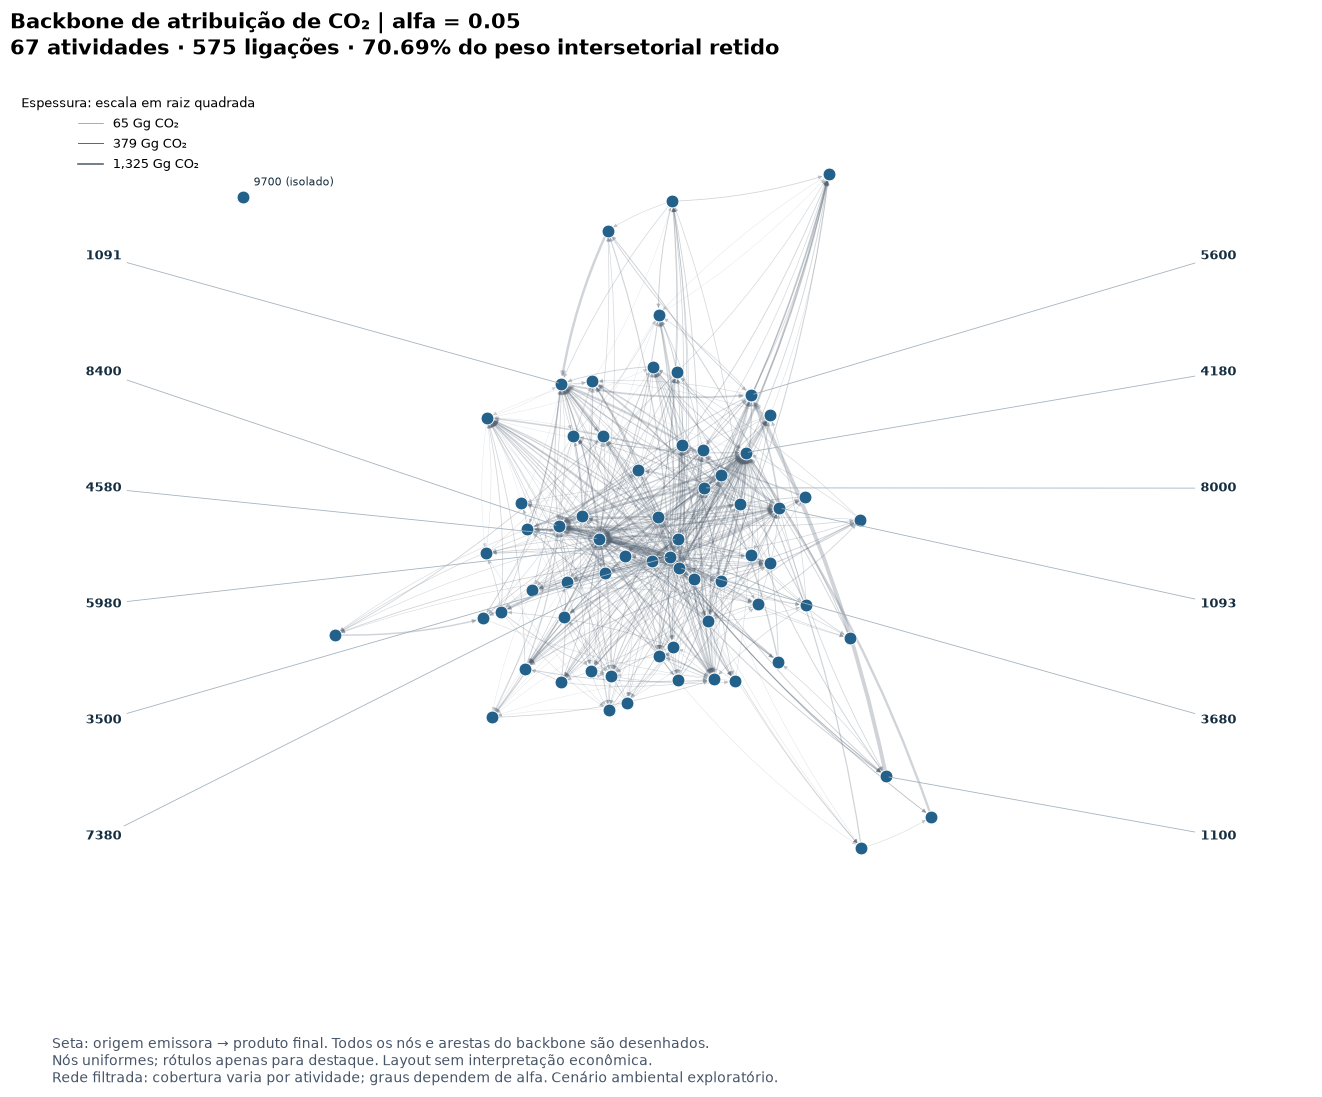

In [22]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from redes.visualizacoes import ROTULOS_ATIVIDADES_IBGE

alfa_visualizacao = 0.05
H_visualizacao = backbones[alfa_visualizacao]
B_visualizacao = matrizes_backbone[alfa_visualizacao]
resumo_visualizacao = resumo_backbones.loc[alfa_visualizacao]
arestas_desenhadas = sorted(H_visualizacao.edges, key=lambda e: (H_visualizacao.edges[e]["weight"], e))
nos_desenhados = list(atividades)
# O mesmo conjunto de atividades orienta os rótulos e o quadro comparativo.
codigos_destaque = list(dict.fromkeys(s_out.nlargest(6).index.tolist() + s_in.nlargest(6).index.tolist()))
rotulos_destaque = {codigo: codigo for codigo in codigos_destaque}
isolados_visuais = sorted(nx.isolates(H_visualizacao))
ativos_visuais = [codigo for codigo in nos_desenhados if codigo not in isolados_visuais]
posicoes = nx.spring_layout(H_visualizacao.subgraph(ativos_visuais), seed=42,
                             weight=None, iterations=300, k=1 / np.sqrt(len(ativos_visuais)))
for i, codigo in enumerate(isolados_visuais):
    posicoes[codigo] = np.array([-0.9 + 0.2 * i, 0.94])
    rotulos_destaque[codigo] = codigo

assert set(nos_desenhados) == set(H_visualizacao.nodes)
assert set(arestas_desenhadas) == set(H_visualizacao.edges)
assert set(posicoes) == set(nos_desenhados)
assert all(np.isfinite(posicao).all() for posicao in posicoes.values())
pesos_desenhados = np.array([H_visualizacao.edges[e]["weight"] for e in arestas_desenhadas])
np.testing.assert_array_equal(pesos_desenhados,
    np.array([B_visualizacao.at[i, j] for i, j in arestas_desenhadas]))
espessuras = 0.15 + 2.6 * np.sqrt(pesos_desenhados / pesos_desenhados.max())
pasta_figuras = raiz / "entrega_final/figuras"
pasta_figuras.mkdir(exist_ok=True)

fig_rede, ax_rede = plt.subplots(figsize=(14, 12), facecolor="white")
nx.draw_networkx_edges(H_visualizacao, posicoes, ax=ax_rede, edgelist=arestas_desenhadas,
    width=espessuras, edge_color="#576574", alpha=0.28, arrows=True, arrowsize=6,
    arrowstyle="-|>", connectionstyle="arc3,rad=0.07", node_size=85)
nx.draw_networkx_nodes(H_visualizacao, posicoes, ax=ax_rede, nodelist=nos_desenhados,
    node_size=85, node_color="#23618A", edgecolors="white", linewidths=0.6)
# Rótulos externos com linhas-guia evitam sobreposição no centro da rede.
centro_rotulos = np.median([posicoes[codigo][0] for codigo in codigos_destaque])
for lado in (-1, 1):
    grupo = [codigo for codigo in codigos_destaque
             if (posicoes[codigo][0] < centro_rotulos) == (lado == -1)]
    grupo = sorted(grupo, key=lambda codigo: posicoes[codigo][1])
    for codigo, altura in zip(grupo, np.linspace(-0.78, 0.78, len(grupo))):
        ax_rede.annotate(codigo, xy=posicoes[codigo], xytext=(lado*1.16, altura),
            ha="right" if lado == -1 else "left", va="center", fontsize=9, fontweight="bold",
            color="#142D40", arrowprops=dict(arrowstyle="-", color="#A5B3BE", linewidth=0.6))
for codigo in isolados_visuais:
    ax_rede.annotate(f"{codigo} (isolado)", xy=posicoes[codigo], xytext=(8, 8), textcoords="offset points",
                    fontsize=8, color="#142D40")
ax_rede.set_title(f"Backbone de atribuição de CO₂ | alfa = {alfa_visualizacao:.2f}\n"
    f"67 atividades · {H_visualizacao.number_of_edges()} ligações · "
    f"{100*resumo_visualizacao.cobertura_global:.2f}% do peso intersetorial retido",
    loc="left", fontsize=15, fontweight="bold", pad=22)
pesos_legenda = np.quantile(pesos_desenhados, [0.25, 0.75, 0.95])
legenda_pesos = [Line2D([0], [0], color="#576574", linewidth=0.15+2.6*np.sqrt(peso/pesos_desenhados.max()),
                        label=f"{peso:,.0f} Gg CO₂") for peso in pesos_legenda]
ax_rede.legend(handles=legenda_pesos, title="Espessura: escala em raiz quadrada", loc="upper left",
               frameon=False, fontsize=9, title_fontsize=9)
ax_rede.set_axis_off()
ax_rede.set_xlim(-1.4, 1.4)
ax_rede.set_ylim(-1.18, 1.24)
fig_rede.text(0.08, 0.055,
    "Seta: origem emissora → produto final. Todos os nós e arestas do backbone são desenhados.\n"
    "Nós uniformes; rótulos apenas para destaque. Layout sem interpretação econômica.\n"
    "Rede filtrada: cobertura varia por atividade; graus dependem de alfa. Cenário ambiental exploratório.",
    fontsize=10, color="#475569", va="bottom")
fig_rede.subplots_adjust(left=0.05, right=0.98, top=0.89, bottom=0.14)
fig_rede.savefig(pasta_figuras / "backbone_alfa_005.png", dpi=200, facecolor="white")
fig_rede.savefig(pasta_figuras / "backbone_alfa_005.svg", facecolor="white")
plt.show()


## 20. Volume, concentração e conectividade em escalas separadas

A seleção para **apresentação** é a união das seis maiores forças de saída e das seis maiores forças de entrada de W. Portanto, as linhas não são um ranking de grau ou uma seleção de nós para a rede. Todos os nós continuam nas matrizes e no desenho anterior.

- **Volume:** forças de W (antes do filtro), em mil Gg de CO₂.
- **Concentração:** números efetivos de destinos e origens em W; valores menores indicam maior concentração.
- **Conectividade selecionada:** graus em alfa 0,05, com intervalos entre os graus em alfa 0,01 e 0,10. O intervalo é sensibilidade a parâmetros, não intervalo de confiança.
- **Cobertura:** parcela do peso externo preservada em cada direção no alfa 0,05. Complementa a cobertura global e qualifica a leitura dos graus.

Azul identifica saída (origem emissora); laranja identifica entrada (produto final). A diagonal não participa de nenhum destes quatro painéis. As contas completas permanecem nas tabelas anteriores.

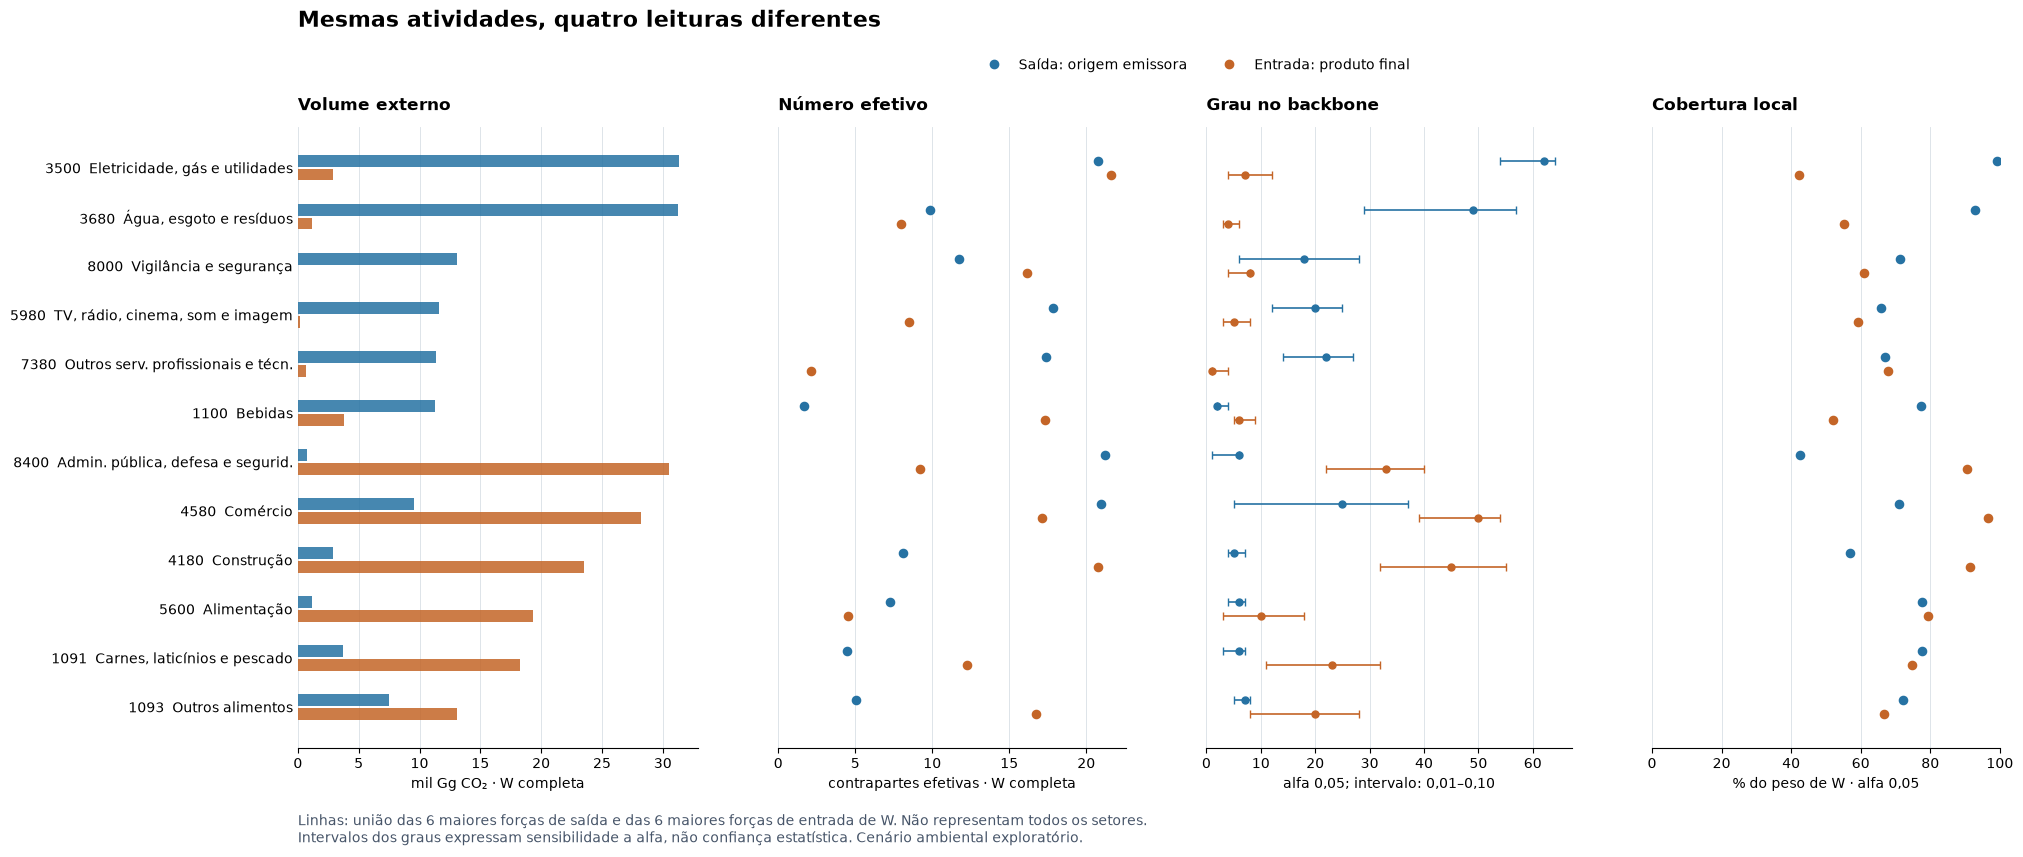

,atividade_nome,forca_saida_Gg,forca_entrada_Gg,numero_efetivo_destinos,...,grau_saida_retido,grau_entrada_retido,cobertura_saida,cobertura_entrada
3500,"Energia elétrica, gás natural e outras utilidades",31317.0425,2923.5034,20.7860,...,62,7,0.9923,0.4214
3680,"Água, esgoto e gestão de resíduos",31229.9618,1164.4865,9.8807,...,49,4,0.9298,0.5518
8000,"Atividades de vigilância, segurança e investig...",13078.6084,7.8662,11.7249,...,18,8,0.7124,0.6099
5980,"Atividades de televisão, rádio, cinema e grav...",11575.5530,142.5308,17.8624,...,20,5,0.6571,0.5921
7380,"Outras atividades profissionais, científicas e...",11358.7861,642.8375,17.3961,...,22,1,0.6711,0.6791
1100,Fabricação de bebidas,11245.0499,3790.9971,1.6964,...,2,6,0.7740,0.5204
8400,"Administração pública, defesa e seguridade social",739.2557,30496.0699,21.1972,...,6,33,0.4249,0.9046
4580,Comércio por atacado e varejo,9547.2084,28210.0339,20.9696,...,25,50,0.7103,0.9654
4180,Construção,2928.4723,23483.7571,8.1003,...,5,45,0.5696,0.9138
5600,Alimentação,1190.1358,19323.4134,7.2885,...,6,10,0.7765,0.7936


In [23]:
linhas_leitura = pd.Index(codigos_destaque)
rotulos_leitura = [f"{codigo}  {ROTULOS_ATIVIDADES_IBGE.get(codigo, nomes.loc[codigo])}"
                   for codigo in linhas_leitura]
y_linhas = np.arange(len(linhas_leitura))
cores_direcoes = {"saida": "#2672A3", "entrada": "#C46527"}
fig_indicadores, eixos = plt.subplots(1, 4, figsize=(23, 9), sharey=True, facecolor="white",
    gridspec_kw={"width_ratios": [1.15, 1, 1.05, 1]})
for sentido, forcas, efetivos, deslocamento in [
    ("saida", s_out, D2_out, -0.14), ("entrada", s_in, D2_in, 0.14)]:
    cor = cores_direcoes[sentido]
    yy = y_linhas + deslocamento
    eixos[0].barh(yy, forcas.loc[linhas_leitura] / 1000, height=0.24, color=cor, alpha=0.85)
    eixos[1].scatter(efetivos.loc[linhas_leitura], yy, color=cor, s=35, zorder=3)
    graus_ref = relatorios_locais[0.05].loc[linhas_leitura, f"grau_{sentido}_retido"]
    graus_min = relatorios_locais[0.01].loc[linhas_leitura, f"grau_{sentido}_retido"]
    graus_max = relatorios_locais[0.10].loc[linhas_leitura, f"grau_{sentido}_retido"]
    eixos[2].errorbar(graus_ref, yy, xerr=np.vstack([graus_ref-graus_min, graus_max-graus_ref]),
        fmt="o", markersize=5, color=cor, capsize=3, linewidth=1.2)
    eixos[3].scatter(100*relatorios_locais[0.05].loc[linhas_leitura, f"cobertura_{sentido}"],
                    yy, color=cor, s=35, zorder=3)

eixos[0].set_yticks(y_linhas, rotulos_leitura, fontsize=10)
eixos[0].invert_yaxis()
for eixo, titulo, unidade in zip(eixos,
    ["Volume externo", "Número efetivo", "Grau no backbone", "Cobertura local"],
    ["mil Gg CO₂ · W completa", "contrapartes efetivas · W completa", "alfa 0,05; intervalo: 0,01–0,10", "% do peso de W · alfa 0,05"]):
    eixo.set_title(titulo, fontsize=12, loc="left", fontweight="bold", pad=12)
    eixo.set_xlabel(unidade, fontsize=10)
    eixo.grid(axis="x", color="#D8DFE5", linewidth=0.6, zorder=0)
    eixo.set_axisbelow(True)
    eixo.spines[["top", "right", "left"]].set_visible(False)
    eixo.tick_params(axis="y", length=0)
    eixo.set_xlim(left=0)
eixos[3].set_xlim(0, 100)
fig_indicadores.suptitle("Mesmas atividades, quatro leituras diferentes", x=0.24, y=0.96,
                        ha="left", fontsize=16, fontweight="bold")
fig_indicadores.legend(handles=[Line2D([0], [0], color=cores_direcoes["saida"], marker="o", linestyle="", label="Saída: origem emissora"),
    Line2D([0], [0], color=cores_direcoes["entrada"], marker="o", linestyle="", label="Entrada: produto final")],
    loc="upper center", bbox_to_anchor=(0.63, 0.92), ncol=2, frameon=False)
fig_indicadores.text(0.24, 0.035,
    "Linhas: união das 6 maiores forças de saída e das 6 maiores forças de entrada de W. Não representam todos os setores.\n"
    "Intervalos dos graus expressam sensibilidade a alfa, não confiança estatística. Cenário ambiental exploratório.",
    ha="left", fontsize=10, color="#475569")
fig_indicadores.subplots_adjust(left=0.24, right=0.98, top=0.83, bottom=0.14, wspace=0.22)
fig_indicadores.savefig(pasta_figuras / "backbone_diagnostico_005.png", dpi=200, facecolor="white")
fig_indicadores.savefig(pasta_figuras / "backbone_diagnostico_005.svg", facecolor="white")
plt.show()

# Conferência das quantidades representadas: não recalcular métricas nem selecionar arestas.
assert set(linhas_leitura) <= set(H_visualizacao.nodes)
assert set(arestas_desenhadas) == set(backbones[0.05].edges)
pd.testing.assert_frame_equal(matrizes_backbone[0.05], B_visualizacao, check_exact=True)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
tabela_leitura = pd.concat([indicadores.loc[linhas_leitura], relatorios_locais[0.05].loc[linhas_leitura].drop(columns="atividade_nome")], axis=1)
display(tabela_leitura[["atividade_nome", "forca_saida_Gg", "forca_entrada_Gg",
    "numero_efetivo_destinos", "numero_efetivo_origens", "grau_saida_retido", "grau_entrada_retido",
    "cobertura_saida", "cobertura_entrada"]].round(4))


### Leitura e limites das figuras

O desenho da rede serve para localizar relações selecionadas; 575 arestas ainda produzem sobreposição, portanto trajetórias aparentes ou posições centrais não sustentam conclusões. O quadro comparativo permite separar volume, concentração e conectividade. Por exemplo, diferenças no grau devem ser lidas junto da amplitude do intervalo de alfa e da cobertura local; não equivalem a diferenças na concentração da rede completa.

Os nomes completos e valores estão na tabela; os recortes de rótulos e linhas são explicitados, enquanto **nenhuma aresta do desenho foi removida**. As figuras não estabelecem eficácia de mitigação nem resolvem a validade da base ambiental.

## 21. Matriz de adjacência do backbone: presença e peso

Os dois painéis representam **as mesmas arestas de alfa 0,05**, com todas as 67 atividades na ordem original do IBGE, idêntica nos dois eixos. A posição $(i,j)$ representa a atribuição da **origem emissora $i$** ao **produto final $j$**; a direção inversa ocupa $(j,i)$.

- **Presença:** $P_{ij}=1$ quando a aresta pertence ao backbone e zero em caso contrário. Todas as células retidas têm a mesma cor, independentemente do peso.
- **Peso:** a mesma célula recebe o peso original $B_{ij}$, em Gg de CO₂. A cor usa **escala logarítmica**, sem normalização por linha ou coluna e sem alteração dos valores. Assim, pesos pequenos permanecem visíveis; diferenças de cor expressam razões entre pesos.

Cinza indica ausência de aresta no backbone, inclusive a diagonal excluída da rede. Isso **não significa emissão nula em F** nem ausência de relação em W. O isolado também permanece nos eixos. Não se aplica outro filtro, agrupamento ou ordenação por indicador. Os códigos nas colunas e os códigos e nomes abreviados nas linhas identificam as mesmas atividades; os nomes completos estão na tabela `indicadores`.


In [24]:
alfa_matriz = 0.05
ordem_matriz = atividades.tolist()
B_matriz = matrizes_backbone[alfa_matriz].loc[ordem_matriz, ordem_matriz].copy(deep=True)
H_matriz = backbones[alfa_matriz]
valores_matriz = B_matriz.to_numpy(copy=True)
presenca_matriz = valores_matriz > 0

# A representação deve reproduzir exatamente pesos, direção e ordem do grafo.
np.testing.assert_array_equal(valores_matriz,
    nx.to_numpy_array(H_matriz, nodelist=ordem_matriz, weight="weight"))
assert B_matriz.index.tolist() == B_matriz.columns.tolist() == ordem_matriz
assert len(ordem_matriz) == H_matriz.number_of_nodes() == 67
assert int(presenca_matriz.sum()) == H_matriz.number_of_edges()
assert not np.diag(presenca_matriz).any()
assert np.isfinite(valores_matriz).all() and (valores_matriz >= 0).all()
np.testing.assert_array_equal(presenca_matriz.sum(axis=1),
    [H_matriz.out_degree(codigo) for codigo in ordem_matriz])
np.testing.assert_array_equal(presenca_matriz.sum(axis=0),
    [H_matriz.in_degree(codigo) for codigo in ordem_matriz])
np.testing.assert_allclose(valores_matriz.sum(), H_matriz.size(weight="weight"))
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)

cobertura_matriz = valores_matriz.sum() / W.to_numpy().sum()
print(f"Matriz validada: {len(ordem_matriz)} atividades, {presenca_matriz.sum()} arestas, "
      f"{100*cobertura_matriz:.2f}% do peso intersetorial de W.")


Matriz validada: 67 atividades, 575 arestas, 70.69% do peso intersetorial de W.


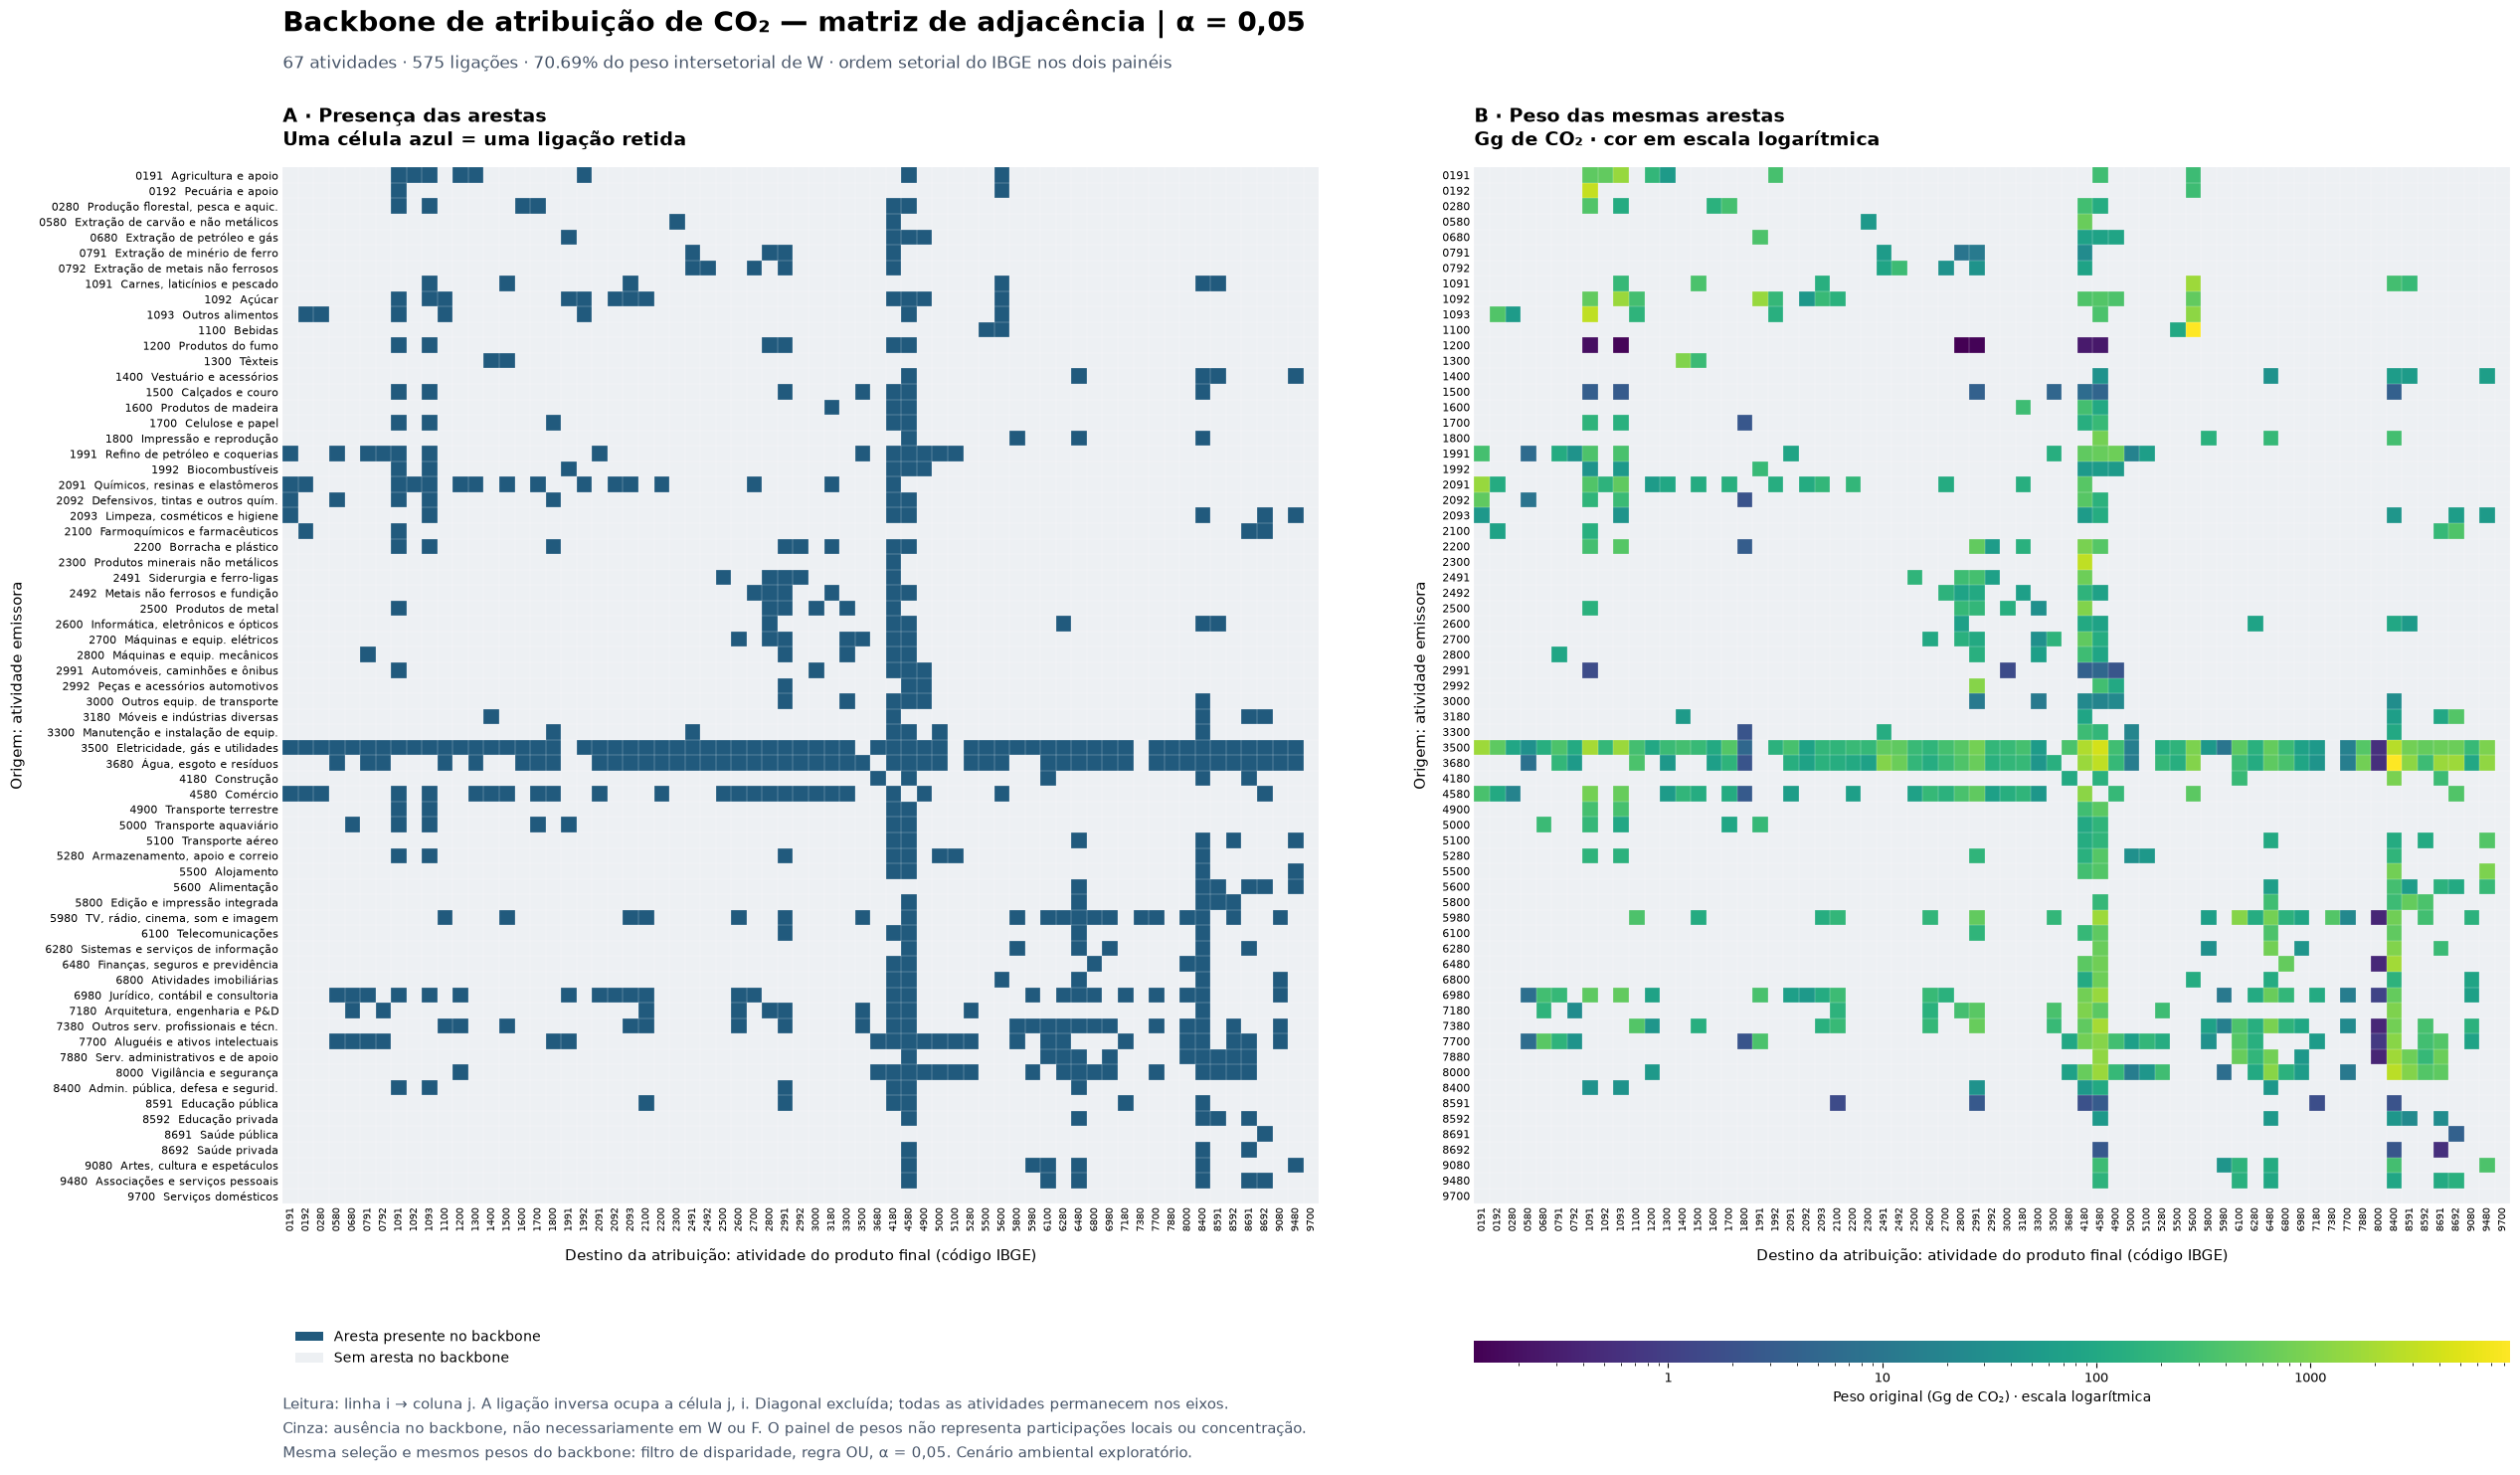

In [25]:
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

cor_ausencia = "#EDF0F3"
cor_presenca = "#215A7D"
cores_presenca = ListedColormap([cor_ausencia, cor_presenca])
cores_pesos = plt.get_cmap("viridis").copy()
cores_pesos.set_bad(cor_ausencia)
# Apenas as células ausentes são mascaradas; nenhuma aresta positiva é ocultada.
pesos_mascarados = np.ma.masked_where(~presenca_matriz, valores_matriz)
pesos_positivos = valores_matriz[presenca_matriz]
norma_pesos = LogNorm(vmin=pesos_positivos.min(), vmax=pesos_positivos.max())
rotulos_linhas_matriz = [
    f"{codigo}  {ROTULOS_ATIVIDADES_IBGE.get(codigo, nomes.loc[codigo])}"
    for codigo in ordem_matriz
]

fig_matriz, eixos_matriz = plt.subplots(1, 2, figsize=(28, 16), facecolor="white")
eixos_matriz[0].imshow(presenca_matriz, cmap=cores_presenca, vmin=0, vmax=1,
                       origin="upper", interpolation="none", aspect="equal")
imagem_pesos = eixos_matriz[1].imshow(pesos_mascarados, cmap=cores_pesos, norm=norma_pesos,
    origin="upper", interpolation="none", aspect="equal")

for numero, eixo in enumerate(eixos_matriz):
    eixo.set_xticks(np.arange(len(ordem_matriz)), ordem_matriz, rotation=90, fontsize=7)
    eixo.set_yticks(np.arange(len(ordem_matriz)),
                   rotulos_linhas_matriz if numero == 0 else ordem_matriz,
                   fontsize=7.7)
    eixo.tick_params(axis="both", which="major", length=0, pad=3)
    eixo.set_xlabel("Destino da atribuição: atividade do produto final (código IBGE)",
                    fontsize=11, labelpad=12)
    eixo.set_ylabel("Origem: atividade emissora", fontsize=11, labelpad=10)
    # Delimitação discreta das células, sem sugerir blocos ou comunidades.
    eixo.set_xticks(np.arange(-0.5, len(ordem_matriz), 1), minor=True)
    eixo.set_yticks(np.arange(-0.5, len(ordem_matriz), 1), minor=True)
    eixo.grid(which="minor", color="white", linewidth=0.18)
    eixo.tick_params(which="minor", bottom=False, left=False)
    for borda in eixo.spines.values():
        borda.set_visible(False)

eixos_matriz[0].set_title("A · Presença das arestas\nUma célula azul = uma ligação retida",
    loc="left", fontsize=14, fontweight="bold", pad=16)
eixos_matriz[1].set_title("B · Peso das mesmas arestas\nGg de CO₂ · cor em escala logarítmica",
    loc="left", fontsize=14, fontweight="bold", pad=16)
eixos_matriz[0].legend(handles=[
    Patch(facecolor=cor_presenca, label="Aresta presente no backbone"),
    Patch(facecolor=cor_ausencia, label="Sem aresta no backbone")],
    loc="upper left", bbox_to_anchor=(0, -0.11), frameon=False, fontsize=10)

fig_matriz.subplots_adjust(left=0.18, right=0.98, top=0.88, bottom=0.20, wspace=0.15)
# Barra externa mantém as duas matrizes com as mesmas dimensões.
posicao_pesos = eixos_matriz[1].get_position()
eixo_barra = fig_matriz.add_axes([posicao_pesos.x0, posicao_pesos.y0 - 0.10,
                                 posicao_pesos.width, 0.014])
barra_pesos = fig_matriz.colorbar(imagem_pesos, cax=eixo_barra, orientation="horizontal")
barra_pesos.ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ",")))
barra_pesos.ax.tick_params(labelsize=9)
barra_pesos.set_label("Peso original (Gg de CO₂) · escala logarítmica", fontsize=10)
barra_pesos.outline.set_visible(False)

fig_matriz.suptitle("Backbone de atribuição de CO₂ — matriz de adjacência | α = 0,05",
    x=0.18, y=0.965, ha="left", fontsize=20, fontweight="bold")
fig_matriz.text(0.18, 0.928,
    f"{len(ordem_matriz)} atividades · {int(presenca_matriz.sum())} ligações · "
    f"{100*cobertura_matriz:.2f}% do peso intersetorial de W · ordem setorial do IBGE nos dois painéis",
    fontsize=12, color="#475569")
fig_matriz.text(0.18, 0.055,
    "Leitura: linha i → coluna j. A ligação inversa ocupa a célula j, i. Diagonal excluída; todas as atividades permanecem nos eixos.\n"
    "Cinza: ausência no backbone, não necessariamente em W ou F. O painel de pesos não representa participações locais ou concentração.\n"
    "Mesma seleção e mesmos pesos do backbone: filtro de disparidade, regra OU, α = 0,05. Cenário ambiental exploratório.",
    fontsize=11, color="#475569", linespacing=1.6)

fig_matriz.savefig(pasta_figuras / "backbone_matriz_adjacencia_005.png", dpi=200, facecolor="white")
fig_matriz.savefig(pasta_figuras / "backbone_matriz_adjacencia_005.svg", facecolor="white")
plt.show()

# A escala de cor e a exportação não modificam nenhum objeto analítico.
np.testing.assert_array_equal(pesos_mascarados.compressed(), valores_matriz[presenca_matriz])
pd.testing.assert_frame_equal(matrizes_backbone[alfa_matriz], B_matriz, check_exact=True)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)


### Como ler os dois painéis

No painel A, uma linha com muitas células azuis indica muitos destinos retidos; uma coluna com muitas células indica muitas origens retidas. São graus do **backbone**, condicionados ao alfa e à cobertura local apresentados nas seções anteriores. Células nas duas posições $(i,j)$ e $(j,i)$ indicam reciprocidade entre atribuições; não representam necessariamente transações recíprocas.

No painel B, cores mais claras indicam maiores volumes absolutos atribuídos entre as atividades. Uma linha com muitas conexões pode conter principalmente pesos pequenos, enquanto poucas conexões podem carregar volume elevado. A cor logarítmica permite visualizar essa amplitude, mas não mede concentração: a comparação de concentração permanece nos números efetivos calculados em W.

As matrizes eliminam o cruzamento de setas e permitem examinar todas as relações selecionadas. A ordenação setorial facilita localizar atividades, mas não identifica comunidades. Para consultar nomes e células individuais, amplie a figura ou abra o SVG exportado. Os recortes por atividade são apresentados na seção seguinte.


## 22. Energia e construção: entradas e saídas do mesmo backbone

Os painéis detalham **todas as arestas incidentes** a energia (3500) e construção (4180) no backbone de **alfa 0,05**, sem reaplicar o filtro. A escolha dessas duas atividades é um recorte de apresentação motivado pelos padrões de linha e coluna da matriz; não altera a rede nem constitui um ranking setorial.

Cada atividade tem dois painéis: **entradas**, de outras origens emissoras para o seu produto final; e **saídas**, da própria origem emissora para produtos finais de outras atividades. Cada barra é uma aresta retida, com comprimento e rótulo em **Gg de CO₂**, em ordem decrescente de peso. Os quatro painéis usam a mesma escala linear, iniciada em zero. Os rótulos numéricos têm uma casa decimal; os pesos sem arredondamento permanecem em `arestas_paineis`.

A cobertura é o peso retido dividido pela força da **mesma atividade e direção em W**, antes do filtro, sem diagonal. As contagens de arestas são apresentadas separadamente da cobertura de volume. A diagonal permanece excluída: uma saída intersetorial pequena não implica baixa emissão própria na conta completa.

As cores reproduzem o campo `motivo` da seleção já calculada:

- **Saída na origem:** somente a cauda de saída da origem é menor que alfa.
- **Entrada no destino:** somente a cauda de entrada do destino é menor que alfa.
- **Ambos:** os dois testes passam.

Portanto, «saída» e «entrada» na legenda identificam a ponta onde o teste passa, **independentemente de qual atividade está em destaque**. Por exemplo, uma saída de energia pode ser retida apenas pelo teste de entrada no destino. A convenção de grau um seria identificada separadamente se estivesse presente.

As tabelas após as figuras registram origem, destino, peso e as duas caudas, sem tratá-las como probabilidades de causalidade. A regra permanece OU e estritamente `cauda < 0,05`; não se recalculam participações nos recortes.


In [26]:
alfa_paineis = 0.05
atividades_paineis = ("3500", "4180")
selecao_paineis = selecoes[alfa_paineis].copy(deep=True)
B_antes_dos_paineis = matrizes_backbone[alfa_paineis].copy(deep=True)
H_paineis = backbones[alfa_paineis]

# Recortar os registros já selecionados, sem novos testes ou cortes de peso.
recortes_paineis = []
resumos_paineis = []
for codigo in atividades_paineis:
    for sentido in ("entrada", "saida"):
        ponta_focal = "destino" if sentido == "entrada" else "origem"
        ponta_contraparte = "origem" if sentido == "entrada" else "destino"
        recorte = selecao_paineis.loc[
            selecao_paineis.retida & selecao_paineis[ponta_focal].eq(codigo)
        ].copy()
        recorte["atividade_focal"] = codigo
        recorte["sentido_painel"] = sentido
        recorte["contraparte"] = recorte[ponta_contraparte]
        recorte["contraparte_nome"] = recorte.contraparte.map(nomes)
        recorte = recorte.sort_values(["peso_Gg", "contraparte"],
                                      ascending=[False, True], kind="stable")
        recortes_paineis.append(recorte)

        arestas_esperadas = set(H_paineis.in_edges(codigo) if sentido == "entrada"
                               else H_paineis.out_edges(codigo))
        arestas_recortadas = set(recorte[["origem", "destino"]].itertuples(index=False, name=None))
        assert arestas_recortadas == arestas_esperadas
        assert recorte.retida.all() and recorte.contraparte.is_unique
        assert not recorte.contraparte.eq(codigo).any()
        for registro in recorte.itertuples(index=False):
            assert registro.peso_Gg == W.at[registro.origem, registro.destino]
            assert registro.peso_Gg == H_paineis.edges[registro.origem, registro.destino]["weight"]
            assert registro.motivo == H_paineis.edges[registro.origem, registro.destino]["motivo"]
        np.testing.assert_array_equal(recorte.retida,
            recorte.cauda_saida.lt(alfa_paineis) | recorte.cauda_entrada.lt(alfa_paineis)
            | recorte.convencao_grau_um)
        motivos_esperados = np.select([
            recorte.convencao_grau_um,
            recorte.selecionada_saida & recorte.selecionada_entrada,
            recorte.selecionada_saida,
            recorte.selecionada_entrada,
        ], ["convencao_grau_um", "ambas", "saida", "entrada"], default="nao_retida")
        np.testing.assert_array_equal(recorte.motivo, motivos_esperados)

        forca_completa = (s_in if sentido == "entrada" else s_out).loc[codigo]
        grau_completo = (k_in if sentido == "entrada" else k_out).loc[codigo]
        peso_retido = recorte.peso_Gg.sum()
        cobertura = peso_retido / forca_completa
        local = relatorios_locais[alfa_paineis].loc[codigo]
        assert len(recorte) == local[f"grau_{sentido}_retido"]
        np.testing.assert_allclose(peso_retido, local[f"forca_{sentido}_retida_Gg"])
        np.testing.assert_allclose(cobertura, local[f"cobertura_{sentido}"])
        resumos_paineis.append({
            "atividade": codigo, "sentido": sentido, "arestas_retidas": len(recorte),
            "arestas_em_W": grau_completo, "peso_retido_Gg": peso_retido,
            "peso_externo_W_Gg": forca_completa, "cobertura_volume_pct": 100*cobertura,
            "somente_saida": recorte.motivo.eq("saida").sum(),
            "somente_entrada": recorte.motivo.eq("entrada").sum(),
            "ambos": recorte.motivo.eq("ambas").sum(),
            "convencao_grau_um": recorte.motivo.eq("convencao_grau_um").sum(),
        })

arestas_paineis = pd.concat(recortes_paineis, ignore_index=True)
resumo_paineis = pd.DataFrame(resumos_paineis).set_index(["atividade", "sentido"])
assert (resumo_paineis[["somente_saida", "somente_entrada", "ambos", "convencao_grau_um"]]
        .sum(axis=1) == resumo_paineis.arestas_retidas).all()
# Uma aresta entre as duas atividades aparece nos dois recortes pertinentes.
# Essas linhas não são somadas para estimar o peso ou o número de arestas da rede.
with pd.option_context("display.max_columns", None):
    display(resumo_paineis.round(4))
print("Recortes validados contra o backbone: pesos, motivos, contagens e coberturas preservados.")


arestas_retidas  arestas_em_W  peso_retido_Gg  \
atividade sentido                                                  
3500      entrada                7            65       1232.0107   
          saida                 62            65      31075.2240   
4180      entrada               45            65      21458.7566   
          saida                  5            65       1667.9644   

                   peso_externo_W_Gg  cobertura_volume_pct  somente_saida  \
atividade sentido                                                           
3500      entrada          2923.5034               42.1416              1   
          saida           31317.0425               99.2278              0   
4180      entrada         23483.7571               91.3770             41   
          saida            2928.4723               56.9568              4   

                   somente_entrada  ambos  convencao_grau_um  
atividade sentido                                             
3500      entrada                5      1                  0  
          saida                 56      6                  0  
4180      entrada                0      4                  0  
          saida                  1      0                  0

Recortes validados contra o backbone: pesos, motivos, contagens e coberturas preservados.


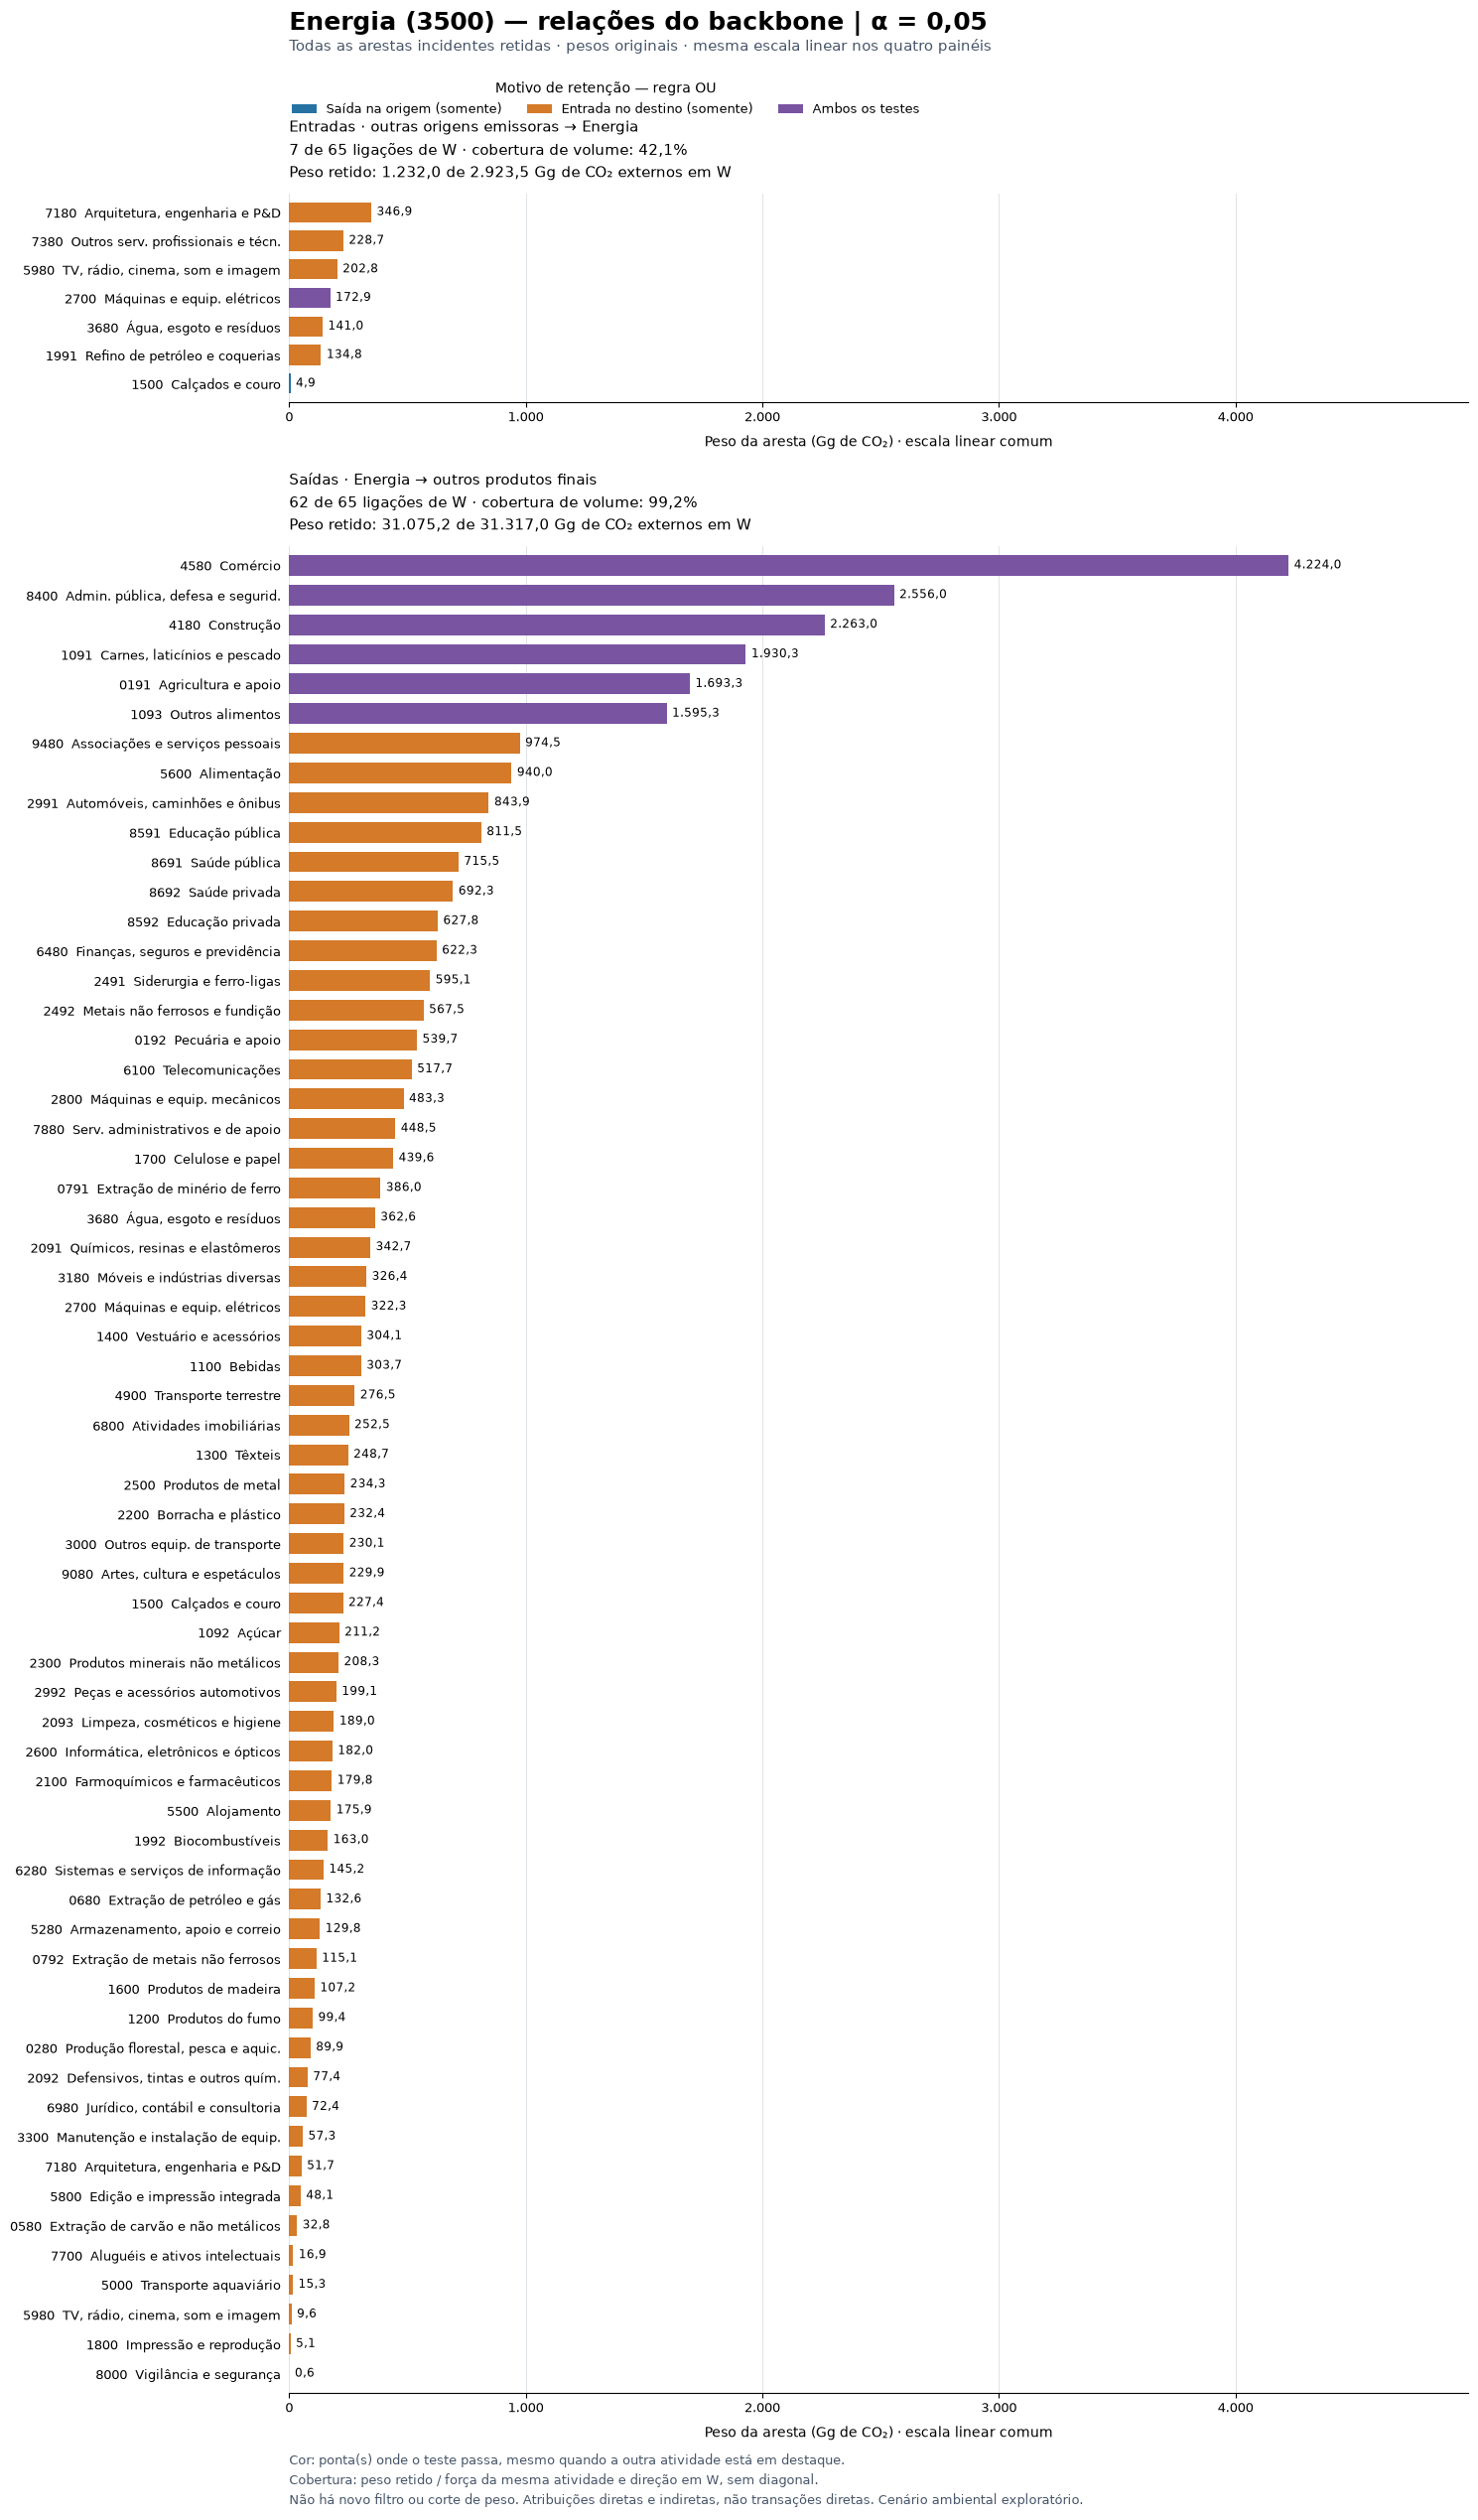

Arestas representadas — Energia elétrica, gás natural e outras utilidades. Caudas calculadas em W completa:


,sentido_painel,origem,destino,peso_Gg,cauda_saida,cauda_entrada,motivo
0,entrada,7180,3500,346.8595,0.062023,0.000309,Entrada no destino (somente)
1,entrada,7380,3500,228.7108,0.272042,0.005442,Entrada no destino (somente)
2,entrada,5980,3500,202.7834,0.322677,0.010045,Entrada no destino (somente)
3,entrada,2700,3500,172.9454,0.002709,0.020188,Ambos os testes
4,entrada,3680,3500,141.0415,0.748493,0.042232,Entrada no destino (somente)
5,entrada,1991,3500,134.7566,0.210056,0.048792,Entrada no destino (somente)
6,entrada,1500,3500,4.9135,0.006608,0.897938,Saída na origem (somente)
7,saida,3500,4580,4223.9929,0.000094,0.000031,Ambos os testes
8,saida,3500,8400,2556.0477,0.004300,0.003689,Ambos os testes
9,saida,3500,4180,2262.9508,0.008228,0.001526,Ambos os testes


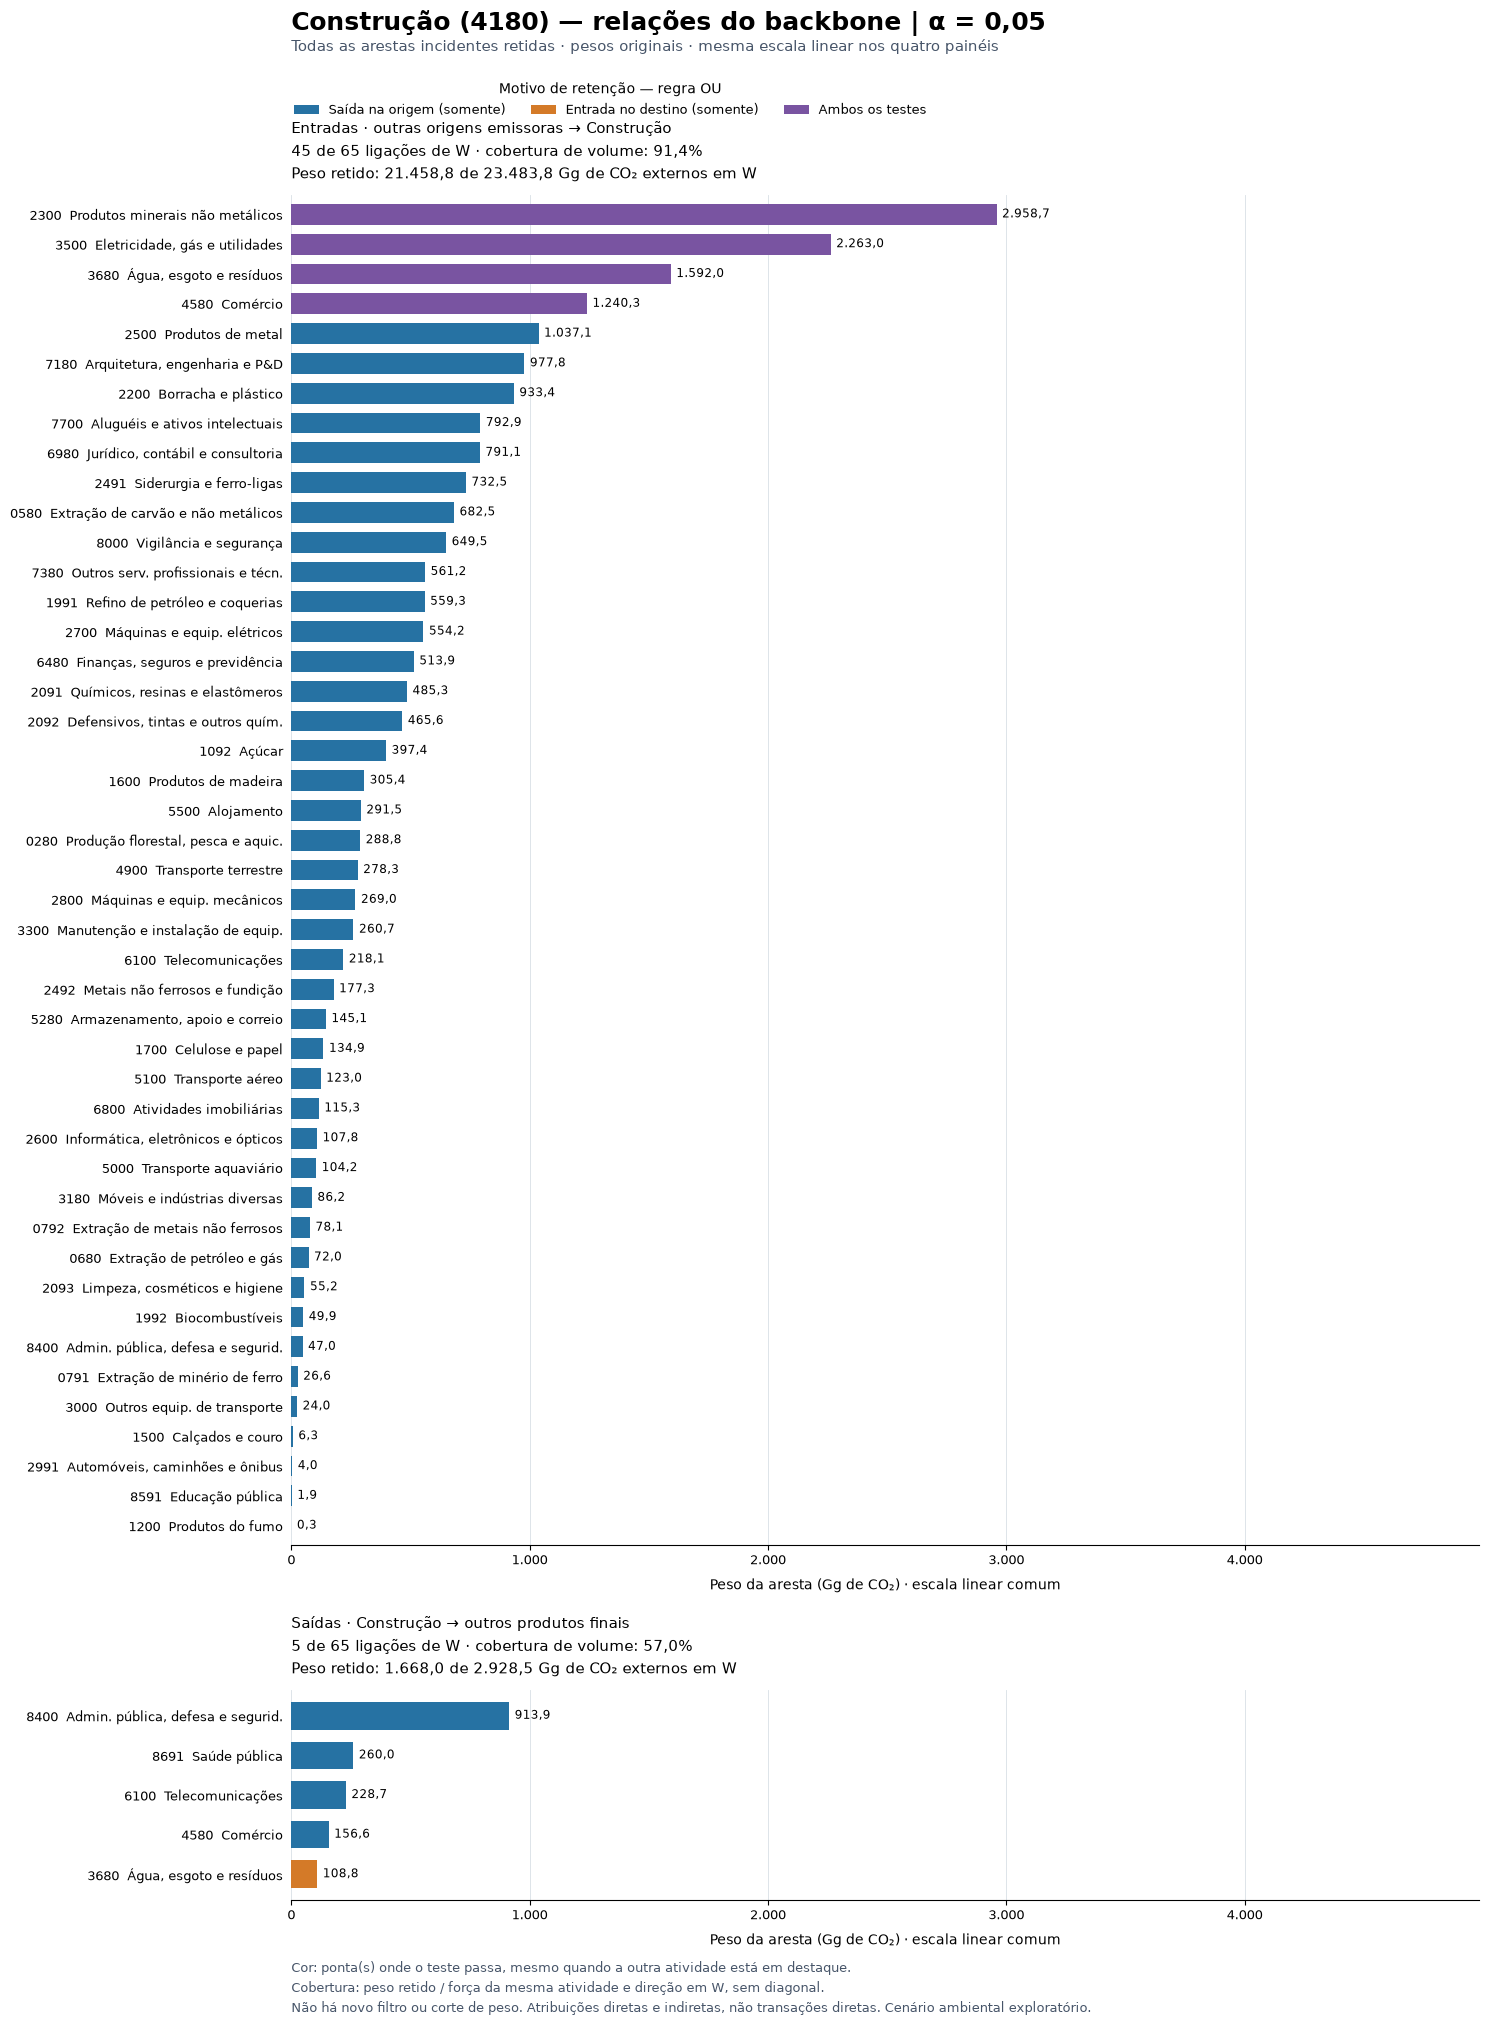

Arestas representadas — Construção. Caudas calculadas em W completa:


,sentido_painel,origem,destino,peso_Gg,cauda_saida,cauda_entrada,motivo
69,entrada,2300,4180,2958.7481,0.000000,0.000181,Ambos os testes
70,entrada,3500,4180,2262.9508,0.008228,0.001526,Ambos os testes
71,entrada,3680,4180,1591.9759,0.035135,0.011191,Ambos os testes
72,entrada,4580,4180,1240.3194,0.000136,0.031031,Ambos os testes
73,entrada,2500,4180,1037.0952,0.000000,0.055538,Saída na origem (somente)
74,entrada,7180,4180,977.8281,0.000283,0.065748,Saída na origem (somente)
75,entrada,2200,4180,933.4068,0.000002,0.074591,Saída na origem (somente)
76,entrada,7700,4180,792.9203,0.005887,0.110996,Saída na origem (somente)
77,entrada,6980,4180,791.0606,0.007944,0.111580,Saída na origem (somente)
78,entrada,2491,4180,732.5278,0.000000,0.131579,Saída na origem (somente)


Figuras e tabelas concluídas; seleção, pesos, W e F permanecem inalterados.


In [27]:
cores_motivos = {"saida": "#2672A3", "entrada": "#D47A28",
                 "ambas": "#7954A1", "convencao_grau_um": "#64748B"}
nomes_motivos = {"saida": "Saída na origem (somente)", "entrada": "Entrada no destino (somente)",
                 "ambas": "Ambos os testes", "convencao_grau_um": "Convenção de grau um"}
nomes_paineis = {"3500": "Energia", "4180": "Construção"}
arquivos_paineis = {"3500": "energia_3500", "4180": "construcao_4180"}
# Um único limite para os quatro painéis: comprimento comparável em Gg de CO₂.
limite_pesos_paineis = 1.18 * arestas_paineis.peso_Gg.max()
figuras_paineis = {}

for codigo in atividades_paineis:
    linhas_atividade = arestas_paineis.loc[arestas_paineis.atividade_focal.eq(codigo)]
    quantidades = [len(linhas_atividade.loc[linhas_atividade.sentido_painel.eq(sentido)])
                  for sentido in ("entrada", "saida")]
    # Altura proporcional ao número de barras mantém todos os rótulos legíveis.
    alturas = [max(2.1, 0.30 * quantidade) for quantidade in quantidades]
    intervalo = 1.45
    altura_figura = sum(alturas) + intervalo + 2.1 + 1.4
    figura, eixos = plt.subplots(2, 1, figsize=(18, altura_figura), facecolor="white",
        gridspec_kw={"height_ratios": alturas})
    figura.subplots_adjust(left=0.32, right=0.98, top=1-2.1/altura_figura,
        bottom=1.4/altura_figura, hspace=2*intervalo/sum(alturas))
    figuras_paineis[codigo] = figura

    figura.suptitle(f"{nomes_paineis[codigo]} ({codigo}) — relações do backbone | α = 0,05",
        x=0.32, y=1-0.25/altura_figura, ha="left", fontsize=18, fontweight="bold")
    figura.text(0.32, 1-0.66/altura_figura,
        "Todas as arestas incidentes retidas · pesos originais · mesma escala linear nos quatro painéis",
        fontsize=10.5, color="#475569")
    motivos_presentes = set(linhas_atividade.motivo)
    figura.legend(handles=[Patch(facecolor=cores_motivos[motivo], label=nomes_motivos[motivo])
        for motivo in cores_motivos if motivo in motivos_presentes],
        title="Motivo de retenção — regra OU", title_fontsize=10, fontsize=9,
        loc="upper left", bbox_to_anchor=(0.315, 1-0.86/altura_figura),
        frameon=False, ncol=3)

    for eixo, sentido in zip(eixos, ("entrada", "saida")):
        recorte = linhas_atividade.loc[linhas_atividade.sentido_painel.eq(sentido)]
        resumo = resumo_paineis.loc[(codigo, sentido)]
        rotulos = [f"{r.contraparte}  {ROTULOS_ATIVIDADES_IBGE.get(r.contraparte, r.contraparte_nome)}"
                   for r in recorte.itertuples(index=False)]
        barras = eixo.barh(np.arange(len(recorte)), recorte.peso_Gg, height=0.70,
                          color=[cores_motivos[motivo] for motivo in recorte.motivo])
        eixo.set_yticks(np.arange(len(recorte)), rotulos, fontsize=9)
        eixo.set_ylim(len(recorte)-0.35, -0.65)
        eixo.set_xlim(0, limite_pesos_paineis)
        eixo.bar_label(barras, labels=[f"{peso:,.1f}".replace(",", "_").replace(".", ",").replace("_", ".")
                                      for peso in recorte.peso_Gg], padding=4, fontsize=8.5)
        eixo.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:,.0f}".replace(",", ".")))
        eixo.tick_params(axis="y", length=0, pad=6)
        eixo.tick_params(axis="x", labelsize=9)
        eixo.grid(axis="x", color="#D8DFE5", linewidth=0.6)
        eixo.set_axisbelow(True)
        eixo.spines[["top", "right", "left"]].set_visible(False)
        eixo.set_xlabel("Peso da aresta (Gg de CO₂) · escala linear comum", fontsize=10, labelpad=8)

        titulo = (f"Entradas · outras origens emissoras → {nomes_paineis[codigo]}"
                  if sentido == "entrada" else
                  f"Saídas · {nomes_paineis[codigo]} → outros produtos finais")
        peso_rotulo = f"{resumo.peso_retido_Gg:,.1f}".replace(",", "_").replace(".", ",").replace("_", ".")
        total_rotulo = f"{resumo.peso_externo_W_Gg:,.1f}".replace(",", "_").replace(".", ",").replace("_", ".")
        cobertura_rotulo = f"{resumo.cobertura_volume_pct:.1f}".replace(".", ",")
        eixo.set_title(f"{titulo}\n"
            f"{int(resumo.arestas_retidas)} de {int(resumo.arestas_em_W)} ligações de W · "
            f"cobertura de volume: {cobertura_rotulo}%\n"
            f"Peso retido: {peso_rotulo} de {total_rotulo} Gg de CO₂ externos em W",
            loc="left", fontsize=11, linespacing=1.5, pad=12)

    figura.text(0.32, 0.22/altura_figura,
        "Cor: ponta(s) onde o teste passa, mesmo quando a outra atividade está em destaque.\n"
        "Cobertura: peso retido / força da mesma atividade e direção em W, sem diagonal.\n"
        "Não há novo filtro ou corte de peso. Atribuições diretas e indiretas, não transações diretas. Cenário ambiental exploratório.",
        fontsize=9, color="#475569", linespacing=1.6, va="bottom")
    nome_arquivo = f"backbone_{arquivos_paineis[codigo]}_005"
    figura.savefig(pasta_figuras / f"{nome_arquivo}.png", dpi=180, facecolor="white")
    figura.savefig(pasta_figuras / f"{nome_arquivo}.svg", facecolor="white")
    plt.show()

    print(f"Arestas representadas — {nomes.loc[codigo]}. Caudas calculadas em W completa:")
    tabela_atividade = linhas_atividade[["sentido_painel", "origem", "destino", "peso_Gg",
                                        "cauda_saida", "cauda_entrada", "motivo"]].copy()
    tabela_atividade["motivo"] = tabela_atividade.motivo.map(nomes_motivos)
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(tabela_atividade.round({"peso_Gg": 4, "cauda_saida": 6, "cauda_entrada": 6}))

pd.testing.assert_frame_equal(selecoes[alfa_paineis], selecao_paineis, check_exact=True)
pd.testing.assert_frame_equal(matrizes_backbone[alfa_paineis], B_antes_dos_paineis, check_exact=True)
pd.testing.assert_frame_equal(W, F.where(~np.eye(len(F), dtype=bool), 0.), check_exact=True)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
print("Figuras e tabelas concluídas; seleção, pesos, W e F permanecem inalterados.")


### Interpretação dos painéis em relação à pergunta

Nossa pergunta é quais relações intersetoriais compõem as diferenças entre as emissões atribuídas pela produção e pela demanda, e como essas relações se organizam em volume, concentração e conectividade. Os painéis permitem identificar **quais atividades participam dessas relações, qual o peso de cada atribuição e em qual ponta ela passa pelo filtro**. Os resultados abaixo se referem ao cenário ambiental exploratório e ao backbone com alfa 0,05.

**O motivo de retenção distingue as duas perspectivas da mesma relação.** Para uma aresta $i\to j$, «saída na origem» significa que o teste sobre a participação $W_{ij}/s_i^{out}$ passa; «entrada no destino», que passa o teste sobre $W_{ij}/s_j^{in}$; «ambos», que os dois passam. As caudas são calculadas em W completa e comparadas estritamente com alfa. As cores identificam o resultado desses testes, não uma prioridade ambiental ou uma probabilidade de causalidade.

| Recorte | Arestas retidas | Só saída na origem | Só entrada no destino | Ambos | Cobertura do volume externo |
|---|---:|---:|---:|---:|---:|
| Entradas de energia | 7 | 1 | 5 | 1 | 42,1% |
| Saídas de energia | 62 | 0 | 56 | 6 | 99,2% |
| Entradas de construção | 45 | 41 | 0 | 4 | 91,4% |
| Saídas de construção | 5 | 4 | 1 | 0 | 57,0% |

As contagens e coberturas estão em `resumo_paineis`; nenhuma dessas arestas foi retida pela convenção de grau um. A cobertura mede volume, não a fração de ligações preservadas.

**Energia aparece como uma origem compartilhada por muitos destinos de demanda final.** Das 62 saídas retidas, 56 permanecem somente pelo teste de entrada no destino. Energia apresenta uma participação saliente no perfil externo recebido por muitas atividades, embora cada destino possa representar uma parcela pequena do volume distribuído por energia. A linha extensa da matriz não significa que seus 62 destinos tenham pesos semelhantes ou igual relevância para a origem.

As outras seis saídas passam pelos dois testes. A relação energia → construção exemplifica essa situação: seus aproximadamente 2.263 Gg representam 7,2% das saídas externas de energia e 9,6% das entradas externas de construção. Uma mesma relação é, portanto, saliente nas duas perspectivas. Essas atribuições incluem efeitos diretos e indiretos; não são apenas transações entre fornecedores e compradores imediatos.

**Construção aparece como um destino importante para diversas origens emissoras.** Das 45 entradas retidas, 41 passam somente pelo teste de saída na origem. Para essas origens, construção representa uma participação saliente no volume externo distribuído, mesmo quando a contribuição individual é pequena no total recebido por construção. Isso explica a presença de barras curtas: baixo peso absoluto e relevância relativa para uma ponta podem coexistir.

**As diferenças de cobertura delimitam a interpretação.** O painel de saídas de energia preserva 99,2% do volume externo correspondente, e o de entradas de construção preserva 91,4%. Eles representam bem os volumes nas direções que caracterizam os papéis predominantes observados. Nas direções inversas, o recorte é mais parcial: as entradas de energia omitem 57,9% do volume externo recebido, e as saídas de construção omitem 43,0% do volume externo distribuído. Uma lista curta não significa que as relações omitidas sejam inexistentes ou desprezíveis em conjunto.

A diagonal também importa: construção tem cerca de 35,91 mil Gg na atribuição de emissões próprias à sua própria demanda final, fora da rede intersetorial. Sua pequena saída externa não implica baixa emissão pela produção. De modo semelhante, graus do backbone não substituem a concentração dos pesos: em W completa, energia tem aproximadamente 20,8 destinos efetivos e construção tem 20,8 origens efetivas, apesar dos diferentes números de arestas selecionadas. Os graus continuam sujeitos à sensibilidade a alfa avaliada anteriormente.

**A conexão com a diferença produção–demanda é contábil e relacional.** Com as matrizes completas,

$$u_i-c_i=s_i^{in}-s_i^{out}.$$

No cenário utilizado, essa diferença é aproximadamente −28,39 mil Gg para energia e +20,56 mil Gg para construção. Os painéis identificam relações que compõem essas diferenças: energia distribui emissões próprias para outros destinos, enquanto construção recebe atribuições de outras origens. Como a cobertura difere entre entradas e saídas, os saldos completos **não devem ser reconstruídos apenas com as barras retidas**.

Os recortes complementam a matriz global e os indicadores de W: conectividade selecionada, volume e concentração respondem a aspectos distintos da pergunta. Uma aresta compartilhada pelos dois recortes não deve ser contada duas vezes em totais da rede. Os resultados descrevem o cenário exploratório, sem estabelecer efeitos de mitigação ou prioridades de política. Nesta etapa, permanece o mesmo filtro, sem novas métricas ou análises.


## 23. Rede com posições fixas e destaque para energia e construção

Esta representação revisa a leitura do desenho por forças da seção 19, mantendo **os mesmos 67 nós, as mesmas 575 arestas e os mesmos pesos do backbone com alfa 0,05**. Os padrões identificados na matriz e nos painéis orientam a apresentação, sem novo filtro ou cálculo de centralidade.

O posicionamento usa o saldo **completo** $u-c$, já calculado: atividades com $c>u$ ficam no semicírculo esquerdo e atividades com $u>c$ no direito. Em cada lado, os códigos seguem a ordem setorial do IBGE, de cima para baixo. O isolado fica abaixo do círculo. As duas vistas têm posições idênticas e mostram toda a rede; o contorno do nó identifica a atividade em destaque.

- **Azul:** saídas da atividade destacada para outros produtos finais.
- **Laranja:** entradas de outras origens emissoras para o produto final da atividade destacada.
- **Cinza:** demais arestas do backbone, com menor opacidade para dar contexto.

As cores indicam direção em relação ao destaque, **não motivo de retenção**. Os motivos permanecem nas cores e tabelas dos painéis da seção 22. A espessura cresce com a raiz quadrada do peso original, com a mesma escala nas duas vistas; a área dos nós é uniforme. Todas as arestas são desenhadas, inclusive as de menor peso. Relações recíprocas são curvadas.

Os lados representam a comparação contábil produção–demanda, não comunidades detectadas. Posição, proximidade e cruzamento de setas não indicam distância econômica ou trajetória produtiva. A classificação dos nós usa F/W completas, enquanto as arestas são as selecionadas no backbone. A matriz continua sendo a representação para consulta exaustiva das relações.


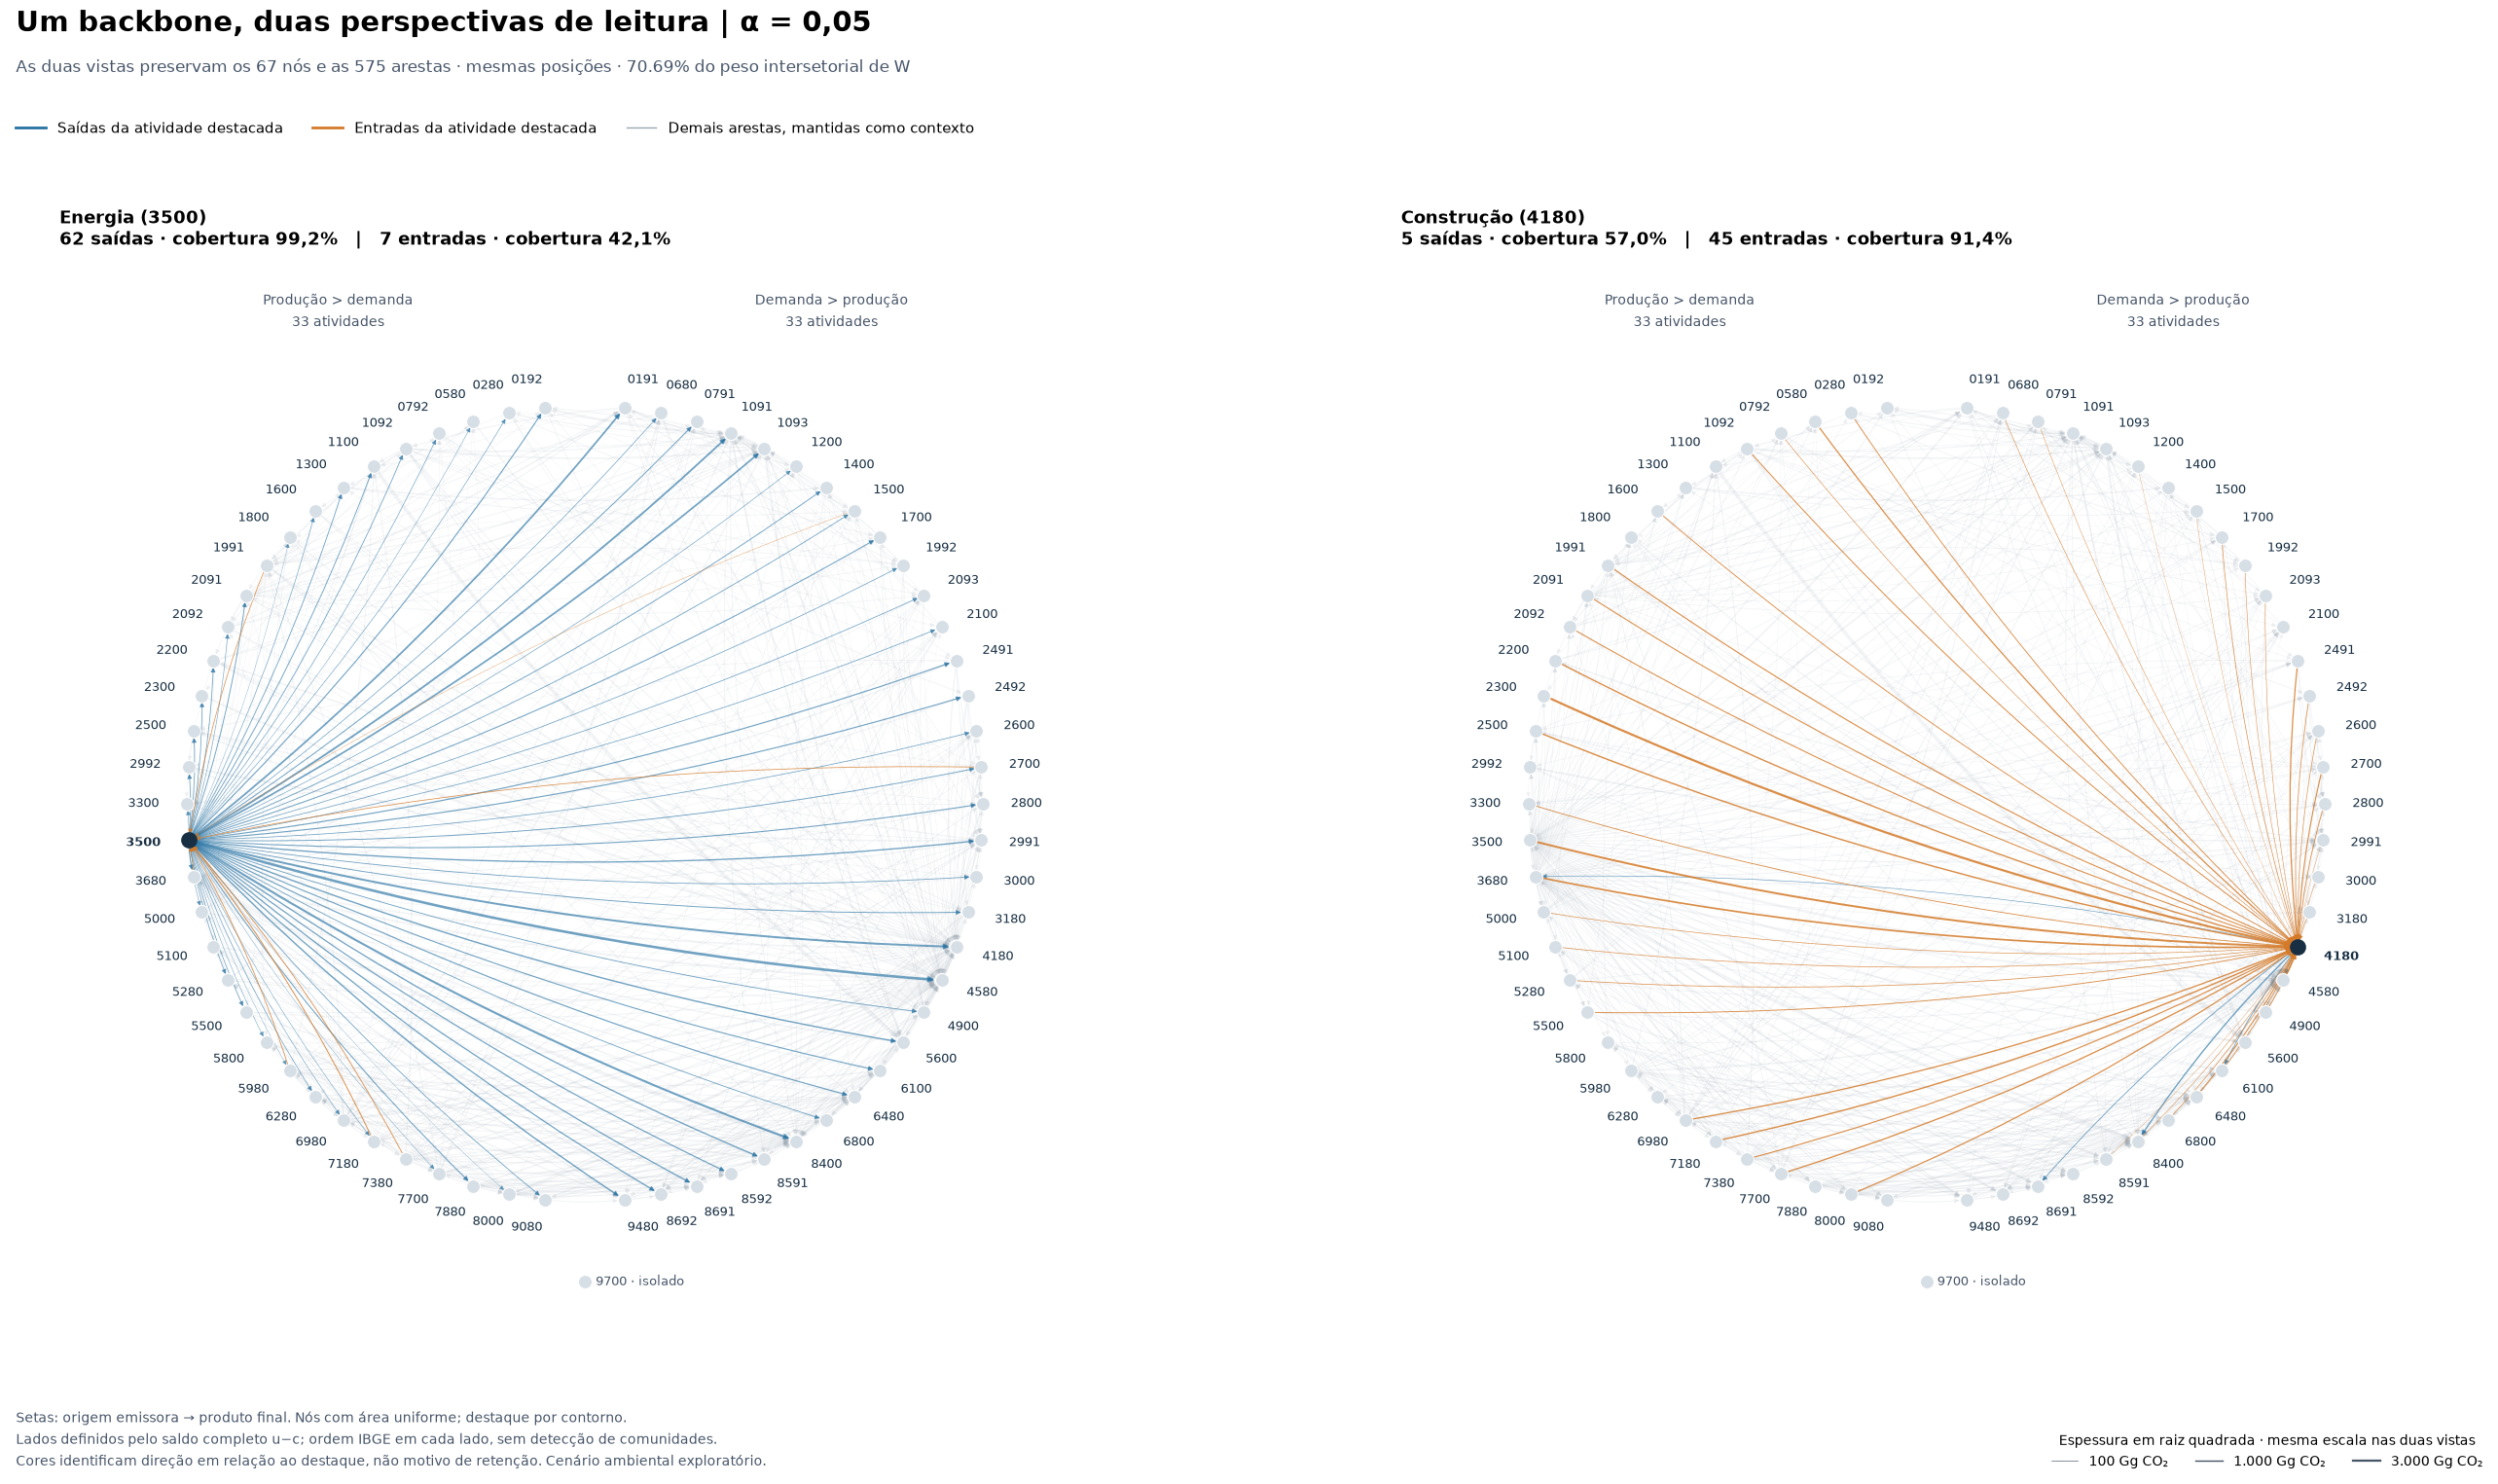

Duas vistas completas: nós, arestas, pesos, direções e coberturas conferidos; F e backbone preservados.


In [28]:
alfa_focos = 0.05
H_focos = backbones[alfa_focos]
B_antes_focos = matrizes_backbone[alfa_focos].copy(deep=True)
arestas_focos = sorted(H_focos.edges, key=lambda e: (H_focos.edges[e]["weight"], e))
isolados_focos = list(nx.isolates(H_focos))
ativos_focos = [codigo for codigo in atividades if codigo not in isolados_focos]
saldo_focos = u - c
# Tolerância somente para reconhecer igualdade numérica na classificação visual.
origens_focos = [codigo for codigo in ativos_focos if saldo_focos.loc[codigo] < -1e-6]
destinos_focos = [codigo for codigo in ativos_focos if saldo_focos.loc[codigo] > 1e-6]
assert set(origens_focos) | set(destinos_focos) == set(ativos_focos)
assert not set(origens_focos) & set(destinos_focos)

posicoes_focos = {}
for grupo, angulos in [
    (origens_focos, np.linspace(np.pi/2+0.10, 3*np.pi/2-0.10, len(origens_focos))),
    (destinos_focos, np.linspace(np.pi/2-0.10, -np.pi/2+0.10, len(destinos_focos))),
]:
    for codigo, angulo in zip(grupo, angulos):
        posicoes_focos[codigo] = np.array([np.cos(angulo), np.sin(angulo)])
for numero, codigo in enumerate(isolados_focos):
    posicoes_focos[codigo] = np.array([0.0+0.20*numero, -1.20])
assert set(posicoes_focos) == set(H_focos.nodes)
assert len(set(tuple(p) for p in posicoes_focos.values())) == len(posicoes_focos)
assert all(np.isfinite(p).all() for p in posicoes_focos.values())

peso_maximo_focos = max(H_focos.edges[e]["weight"] for e in arestas_focos)
fig_focos, eixos_focos = plt.subplots(1, 2, figsize=(28, 16), facecolor="white")
for eixo, codigo in zip(eixos_focos, ("3500", "4180")):
    entradas = [e for e in arestas_focos if e[1] == codigo]
    saidas = [e for e in arestas_focos if e[0] == codigo]
    contexto = [e for e in arestas_focos if codigo not in e]
    assert len(contexto)+len(entradas)+len(saidas) == H_focos.number_of_edges()
    assert set(contexto) | set(entradas) | set(saidas) == set(H_focos.edges)
    assert not set(entradas) & set(saidas)
    for lista, cor, opacidade in [
        (contexto, "#9AA7B4", 0.12), (saidas, "#2672A3", 0.65), (entradas, "#D47A28", 0.85),
    ]:
        espessuras_focos = [0.20+2.4*np.sqrt(H_focos.edges[e]["weight"]/peso_maximo_focos)
                            for e in lista]
        nx.draw_networkx_edges(H_focos, posicoes_focos, ax=eixo, edgelist=lista,
            width=espessuras_focos, edge_color=cor, alpha=opacidade, arrows=True,
            arrowsize=7, arrowstyle="-|>", connectionstyle="arc3,rad=0.055", node_size=100)
    outros_nos = [no for no in atividades if no != codigo]
    nx.draw_networkx_nodes(H_focos, posicoes_focos, ax=eixo, nodelist=outros_nos,
        node_size=100, node_color="#D7DFE6", edgecolors="white", linewidths=0.7)
    nx.draw_networkx_nodes(H_focos, posicoes_focos, ax=eixo, nodelist=[codigo],
        node_size=100, node_color="#182F43", edgecolors="#182F43", linewidths=2)
    for no in ativos_focos:
        ponto = posicoes_focos[no]
        posicao_rotulo = 1.07*ponto
        eixo.text(*posicao_rotulo, no, ha="right" if ponto[0]<0 else "left", va="center",
                  fontsize=9, fontweight="bold" if no == codigo else "normal",
                  color="#182F43", bbox=dict(facecolor="white", edgecolor="none", pad=0.3))
    for no in isolados_focos:
        eixo.annotate(f"{no} · isolado", xy=posicoes_focos[no], xytext=(8, 0),
            textcoords="offset points", fontsize=9, va="center", color="#475569")
    eixo.text(-0.62, 1.20, f"Produção > demanda\n{len(origens_focos)} atividades", ha="center",
               fontsize=10, color="#475569", linespacing=1.5)
    eixo.text(0.62, 1.20, f"Demanda > produção\n{len(destinos_focos)} atividades", ha="center",
               fontsize=10, color="#475569", linespacing=1.5)
    local_foco = relatorios_locais[alfa_focos].loc[codigo]
    cobertura_saida_rotulo = f"{100*local_foco.cobertura_saida:.1f}".replace(".", ",")
    cobertura_entrada_rotulo = f"{100*local_foco.cobertura_entrada:.1f}".replace(".", ",")
    nome_foco = "Energia" if codigo == "3500" else "Construção"
    eixo.set_title(f"{nome_foco} ({codigo})\n"
        f"{len(saidas)} saídas · cobertura {cobertura_saida_rotulo}%   |   "
        f"{len(entradas)} entradas · cobertura {cobertura_entrada_rotulo}%",
        fontsize=13, loc="left", fontweight="bold", pad=22)
    assert len(saidas) == local_foco.grau_saida_retido
    assert len(entradas) == local_foco.grau_entrada_retido
    eixo.set_xlim(-1.32, 1.32)
    eixo.set_ylim(-1.33, 1.33)
    eixo.set_aspect("equal")
    eixo.set_axis_off()

fig_focos.suptitle("Um backbone, duas perspectivas de leitura | α = 0,05",
    x=0.055, y=0.97, ha="left", fontsize=21, fontweight="bold")
fig_focos.text(0.055, 0.93,
    f"As duas vistas preservam os {H_focos.number_of_nodes()} nós e as "
    f"{H_focos.number_of_edges()} arestas · mesmas posições · "
    f"{100*resumo_backbones.at[alfa_focos, 'cobertura_global']:.2f}% do peso intersetorial de W",
    fontsize=12, color="#475569")
fig_focos.legend(handles=[
    Line2D([0], [0], color="#2672A3", linewidth=2, label="Saídas da atividade destacada"),
    Line2D([0], [0], color="#D47A28", linewidth=2, label="Entradas da atividade destacada"),
    Line2D([0], [0], color="#9AA7B4", linewidth=1, label="Demais arestas, mantidas como contexto")],
    loc="upper left", bbox_to_anchor=(0.05, 0.907), ncol=3, frameon=False, fontsize=11)
pesos_guia_focos = (100, 1000, 3000)
fig_focos.legend(handles=[Line2D([0], [0], color="#475569",
    linewidth=0.20+2.4*np.sqrt(peso/peso_maximo_focos), label=f"{peso:,} Gg CO₂".replace(",", "."))
    for peso in pesos_guia_focos], title="Espessura em raiz quadrada · mesma escala nas duas vistas",
    loc="lower right", bbox_to_anchor=(0.965, 0.025), ncol=3, frameon=False, fontsize=10, title_fontsize=10)
fig_focos.text(0.055, 0.035,
    "Setas: origem emissora → produto final. Nós com área uniforme; destaque por contorno.\n"
    "Lados definidos pelo saldo completo u−c; ordem IBGE em cada lado, sem detecção de comunidades.\n"
    "Cores identificam direção em relação ao destaque, não motivo de retenção. Cenário ambiental exploratório.",
    fontsize=10, color="#475569", linespacing=1.6)
fig_focos.subplots_adjust(left=0.04, right=0.98, top=0.80, bottom=0.12, wspace=0.10)
fig_focos.savefig(pasta_figuras / "backbone_focos_energia_construcao_005.png", dpi=180, facecolor="white")
fig_focos.savefig(pasta_figuras / "backbone_focos_energia_construcao_005.svg", facecolor="white")
plt.show()

pd.testing.assert_frame_equal(matrizes_backbone[alfa_focos], B_antes_focos, check_exact=True)
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
np.testing.assert_array_equal(nx.to_numpy_array(H_focos, nodelist=atividades.tolist(), weight="weight"),
                              B_antes_focos.to_numpy())
print("Duas vistas completas: nós, arestas, pesos, direções e coberturas conferidos; F e backbone preservados.")


### Alcance da nova representação

As vistas separam destaque e contexto para mostrar a assimetria de energia como origem e construção como destino, com as coberturas locais informadas. A organização fixa elimina a interpretação indevida de posições centrais do layout por forças e permite comparar exatamente os mesmos nós nas duas vistas. O posicionamento foi definido a partir de informação contábil conhecida: a separação entre os lados não é um resultado de detecção de grupos.

A presença de muitas setas azuis ou laranja não mede concentração e não substitui os pesos e motivos dos painéis. As 575 arestas continuam causando cruzamentos; a leitura individual e a reciprocidade devem ser verificadas na matriz ou nas tabelas. Os nós de um mesmo lado também podem se conectar entre si. Os segmentos não são caminhos produtivos que possam ser concatenados. Esta figura complementa as representações anteriores, com a seleção de arestas inalterada.


## 24. Exportação das figuras para o relatório

As versões abaixo usam os mesmos dados e seleções das seções anteriores. A exportação em PDF vetorial adapta fontes, legendas e paginação ao papel A4. Os dois painéis da matriz e as duas vistas da rede são exportados separadamente para preservar os rótulos. Os painéis completos do anexo mantêm todas as arestas: as 62 saídas de energia são repartidas em duas páginas, em sequência, sem novo corte analítico. Pesos, motivos e denominadores de cobertura permanecem os mesmos. As funções locais servem apenas para repetir desenhos e formatos de número.


In [29]:
from matplotlib.ticker import MaxNLocator

pasta_relatorio = raiz / "entrega_final/entrega/figuras"
pasta_relatorio.mkdir(exist_ok=True)

# Dois painéis da mesma matriz, em páginas distintas, com nomes e códigos legíveis.
for tipo, matriz, mapa, norma in [
    ("presenca", presenca_matriz, cores_presenca, None),
    ("peso", pesos_mascarados, cores_pesos, norma_pesos),
]:
    fig_export, ax_export = plt.subplots(figsize=(9.7, 5.65))
    imagem = ax_export.imshow(matriz, cmap=mapa, norm=norma, origin="upper",
                              interpolation="none", aspect="equal")
    ax_export.set_xticks(np.arange(67), ordem_matriz, rotation=90, fontsize=6.0)
    ax_export.set_yticks(np.arange(67), rotulos_linhas_matriz, fontsize=6.3)
    ax_export.tick_params(length=0, pad=2)
    ax_export.set_xlabel("Produto final (destino da atribuição)", fontsize=8, labelpad=5)
    ax_export.set_ylabel("Origem emissora", fontsize=8, labelpad=5)
    for borda in ax_export.spines.values(): borda.set_visible(False)
    fig_export.subplots_adjust(left=0.32, right=0.94, top=0.995, bottom=0.105)
    if tipo == "peso":
        barra = fig_export.colorbar(imagem, ax=ax_export, fraction=0.025, pad=0.025)
        barra.ax.tick_params(labelsize=7)
        barra.set_label("Gg de CO₂ · escala logarítmica", fontsize=8)
    fig_export.savefig(pasta_relatorio / f"matriz_{tipo}.pdf", facecolor="white")
    plt.close(fig_export)

# Quadro dos mesmos indicadores e das mesmas 12 atividades já apresentadas.
fig_export, axs = plt.subplots(1, 4, figsize=(9.7, 4.7), sharey=True,
                               gridspec_kw={"width_ratios": [1.1, 1, 1.05, 1]})
for sentido, forcas, efetivos, deslocamento in [
    ("saida", s_out, D2_out, -0.14), ("entrada", s_in, D2_in, 0.14)]:
    cor = cores_direcoes[sentido]
    yy = y_linhas + deslocamento
    axs[0].barh(yy, forcas.loc[linhas_leitura]/1000, height=0.24, color=cor)
    axs[1].scatter(efetivos.loc[linhas_leitura], yy, color=cor, s=12)
    graus = relatorios_locais[.05].loc[linhas_leitura, f"grau_{sentido}_retido"]
    menor = relatorios_locais[.01].loc[linhas_leitura, f"grau_{sentido}_retido"]
    maior = relatorios_locais[.10].loc[linhas_leitura, f"grau_{sentido}_retido"]
    axs[2].errorbar(graus, yy, xerr=np.vstack([graus-menor, maior-graus]),
                   fmt="o", markersize=3, color=cor, capsize=2, linewidth=.7)
    axs[3].scatter(100*relatorios_locais[.05].loc[linhas_leitura, f"cobertura_{sentido}"], yy,
                   color=cor, s=12)
axs[0].set_yticks(y_linhas, rotulos_leitura, fontsize=7)
axs[0].invert_yaxis()
for ax, titulo, unidade in zip(axs,
    ["A · Volume", "B · Número efetivo", "C · Grau retido", "D · Cobertura"],
    ["mil Gg CO₂\nW completa", "Contrapartes\nW completa", "α = 0,05\nintervalo: 0,01–0,10", "% do peso de W\nα = 0,05"]):
    ax.set_title(titulo, fontsize=8, loc="left", pad=9)
    ax.set_xlabel(unidade, fontsize=7)
    ax.set_xlim(left=0)
    ax.xaxis.set_major_locator(MaxNLocator(4))
    ax.tick_params(axis="x", labelsize=7)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#D8DFE5", linewidth=.4)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
axs[3].set_xlim(0,100)
fig_export.legend(handles=[Line2D([0],[0],color=cores_direcoes["saida"],marker="o",linestyle="",markersize=4,label="Saída"),
    Line2D([0],[0],color=cores_direcoes["entrada"],marker="o",linestyle="",markersize=4,label="Entrada")],
    loc="upper center", bbox_to_anchor=(.64,1), ncol=2, frameon=False, fontsize=8)
fig_export.subplots_adjust(left=.30,right=.98,top=.89,bottom=.16,wspace=.35)
fig_export.savefig(pasta_relatorio / "indicadores.pdf",facecolor="white")
plt.close(fig_export)

# Mesmas posições e arestas da figura de foco, uma atividade por página.
for codigo in ("3500", "4180"):
    fig_export, ax = plt.subplots(figsize=(6.3, 6.8))
    for lista, cor, opacidade in [
        ([e for e in arestas_focos if codigo not in e], "#9AA7B4", .15),
        ([e for e in arestas_focos if e[0]==codigo], "#2672A3", .72),
        ([e for e in arestas_focos if e[1]==codigo], "#D47A28", .88),
    ]:
        nx.draw_networkx_edges(H_focos,posicoes_focos,ax=ax,edgelist=lista,
            width=[.09+1.1*np.sqrt(H_focos.edges[e]["weight"]/peso_maximo_focos) for e in lista],
            edge_color=cor,alpha=opacidade,arrows=True,arrowsize=4,
            arrowstyle="-|>",connectionstyle="arc3,rad=.055",node_size=22)
    nx.draw_networkx_nodes(H_focos,posicoes_focos,ax=ax,nodelist=list(atividades),node_size=22,
        node_color=["#182F43" if no==codigo else "#D7DFE6" for no in atividades],
        edgecolors="white",linewidths=.4)
    for no in ativos_focos:
        ponto=posicoes_focos[no]
        angulo_rotulo = np.degrees(np.arctan2(ponto[1],ponto[0]))
        if ponto[0]<0: angulo_rotulo += 180
        ax.text(*(1.065*ponto),no,ha="right" if ponto[0]<0 else "left",va="center",
            rotation=angulo_rotulo,rotation_mode="anchor",fontsize=6.7,
            fontweight="bold" if no==codigo else "normal",color="#182F43")
    for no in isolados_focos:
        ax.annotate(f"{no} · isolado",xy=posicoes_focos[no],xytext=(5,0),textcoords="offset points",
                    fontsize=7,va="center",color="#475569")
    ax.text(-.62,1.19,"Produção > demanda\n33 atividades",ha="center",fontsize=8,linespacing=1.5)
    ax.text(.62,1.19,"Demanda > produção\n33 atividades",ha="center",fontsize=8,linespacing=1.5)
    ax.set_xlim(-1.30,1.30);ax.set_ylim(-1.30,1.30);ax.set_aspect("equal");ax.set_axis_off()
    fig_export.legend(handles=[Line2D([0],[0],color="#2672A3",label="Saídas do destaque"),
        Line2D([0],[0],color="#D47A28",label="Entradas no destaque"),
        Line2D([0],[0],color="#9AA7B4",label="Demais arestas")],
        loc="lower center",bbox_to_anchor=(.5,.01),ncol=3,frameon=False,fontsize=7)
    fig_export.subplots_adjust(left=.01,right=.99,top=.99,bottom=.07)
    fig_export.savefig(pasta_relatorio / f"rede_foco_{codigo}.pdf",facecolor="white")
    plt.close(fig_export)

# Paginação dos painéis completos: todas as linhas continuam representadas.
partes_anexo = [
    ("energia_1", "3500", [("entrada",0,7),("saida",0,31)]),
    ("energia_2", "3500", [("saida",31,62)]),
    ("construcao", "4180", [("entrada",0,45),("saida",0,5)]),
]
linhas_exportadas = []
for nome_export, codigo, partes in partes_anexo:
    recortes = []
    for sentido, inicio, fim in partes:
        perfil = arestas_paineis.loc[arestas_paineis.atividade_focal.eq(codigo)
                                     & arestas_paineis.sentido_painel.eq(sentido)]
        recorte = perfil.iloc[inicio:fim]
        recortes.append((sentido,inicio,recorte,len(perfil)))
        linhas_exportadas.extend(recorte.index.tolist())
    alturas = [max(.7,.14*len(recorte)) for _,_,recorte,_ in recortes]
    altura_fig = sum(alturas)+.95+.90*(len(recortes)-1)
    fig_export, eixos = plt.subplots(len(recortes),1,figsize=(6.3,altura_fig),squeeze=False,
                                    gridspec_kw={"height_ratios":alturas})
    fig_export.subplots_adjust(left=.42,right=.99,top=1-.65/altura_fig,bottom=.30/altura_fig,
                               hspace=1.80/sum(alturas) if len(recortes)>1 else 0)
    for ax, (sentido,inicio,recorte,total) in zip(eixos[:,0],recortes):
        barras = ax.barh(np.arange(len(recorte)),recorte.peso_Gg,height=.72,
                        color=[cores_motivos[m] for m in recorte.motivo])
        ax.set_yticks(np.arange(len(recorte)),
            [f"{r.contraparte} {ROTULOS_ATIVIDADES_IBGE.get(r.contraparte,r.contraparte_nome)}"
             for r in recorte.itertuples(index=False)],fontsize=6.8)
        ax.set_ylim(len(recorte)-.35,-.65);ax.set_xlim(0,limite_pesos_paineis)
        ax.bar_label(barras,labels=[f"{v:,.1f}".replace(",","_").replace(".",",").replace("_",".")
                                   for v in recorte.peso_Gg],padding=2,fontsize=6.3)
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v,_:f"{v:,.0f}".replace(",",".")))
        ax.tick_params(axis="x",labelsize=7);ax.tick_params(axis="y",length=0,pad=3)
        ax.grid(axis="x",color="#D8DFE5",linewidth=.4);ax.set_axisbelow(True)
        ax.spines[["top","right","left"]].set_visible(False)
        ax.set_xlabel("Gg de CO₂ · escala linear comum",fontsize=7,labelpad=3)
        resumo=resumo_paineis.loc[(codigo,sentido)]
        rotulo = "Entradas: origens emissoras" if sentido=="entrada" else "Saídas: produtos finais"
        cobertura=f"{resumo.cobertura_volume_pct:.1f}".replace(".",",")
        ax.set_title(f"{rotulo} · {total} arestas · cobertura {cobertura}%\n"
                     f"Linhas {inicio+1}–{inicio+len(recorte)} de {total}, por peso decrescente",
                     fontsize=7.5,loc="left",pad=8)
    fig_export.savefig(pasta_relatorio / f"anexo_{nome_export}.pdf",facecolor="white")
    plt.close(fig_export)
assert sorted(linhas_exportadas)==sorted(arestas_paineis.index.tolist())
pd.testing.assert_frame_equal(matrizes_backbone[.05],B_antes_focos,check_exact=True)
pd.testing.assert_frame_equal(F,F_antes_da_rede,check_exact=True)
print("Exportadas 8 figuras vetoriais para o relatório; todas as 119 linhas dos recortes foram preservadas.")


Exportadas 8 figuras vetoriais para o relatório; todas as 119 linhas dos recortes foram preservadas.


## 25. Composição dos perfis e sensibilidade dos casos

Esta etapa aprofunda os casos já utilizados no artigo. Energia e água/resíduos são as duas maiores forças de saída; construção é a terceira maior força de entrada. A escolha permite comparar volumes próximos com concentrações diferentes e os papéis de origem e destino. São exemplos descritivos, sem pretensão de representar todos os perfis da economia.

São examinados os cinco perfis completos: saídas de energia e de água/resíduos, entradas de construção e as direções inversas de energia e construção. As cinco maiores contrapartes são destacadas para exposição, mantendo explícito o peso das demais. Essa ordenação não altera W nem define outro backbone. A sensibilidade consulta as mesmas seleções de alfa 0,01, 0,05 e 0,10, registrando tanto a presença das principais relações quanto seu motivo de retenção.


In [30]:
# Os três casos já utilizados no artigo são situados na distribuição completa.
colunas_contexto = ["forca_saida_Gg", "forca_entrada_Gg",
                    "numero_efetivo_destinos", "numero_efetivo_origens"]
postos_contexto = indicadores[colunas_contexto].rank(ascending=False, method="average")
contexto_casos = indicadores.loc[["3500", "3680", "4180"],
    ["atividade_nome", "c_producao", "u_demanda", "diagonal_F"] + colunas_contexto].copy()
for coluna in colunas_contexto:
    contexto_casos[f"posto_{coluna}"] = postos_contexto.loc[contexto_casos.index, coluna]
contexto_casos["diagonal_pct_c"] = 100 * contexto_casos.diagonal_F / contexto_casos.c_producao
contexto_casos["diagonal_pct_u"] = 100 * contexto_casos.diagonal_F / contexto_casos.u_demanda
display(contexto_casos.round(4))
display(indicadores[["numero_efetivo_destinos", "numero_efetivo_origens"]].agg(["min", "median", "max"]).round(4))



,atividade_nome,c_producao,u_demanda,diagonal_F,forca_saida_Gg,forca_entrada_Gg,numero_efetivo_destinos,numero_efetivo_origens,posto_forca_saida_Gg,posto_forca_entrada_Gg,posto_numero_efetivo_destinos,posto_numero_efetivo_origens,diagonal_pct_c,diagonal_pct_u
3500,"Energia elétrica, gás natural e outras utilidades",56620.6514,28227.1123,25303.6089,31317.0425,2923.5034,20.7860,21.5891,1.0,22.0,9.0,5.0,44.6897,89.6429
3680,"Água, esgoto e gestão de resíduos",51802.2357,21736.7603,20572.2739,31229.9618,1164.4865,9.8807,7.9758,2.0,46.0,40.0,59.0,39.7131,94.6428
4180,Construção,38841.7771,59397.0619,35913.3049,2928.4723,23483.7571,8.1003,20.7631,28.0,3.0,47.0,10.0,92.4605,60.4631


,numero_efetivo_destinos,numero_efetivo_origens
min,1.5754,2.1336
median,11.5008,13.9282
max,25.0447,22.1019


In [31]:
# Ordenar contrapartes é uma escolha de exposição; os perfis completos têm 65 ligações.
# As participações usam W antes do filtro e excluem a diagonal em todas as direções.
casos_perfis = [("3500", "saida"), ("3680", "saida"), ("4180", "entrada"),
                ("3500", "entrada"), ("4180", "saida")]
linhas_perfis = []
linhas_resumo_perfis = []
selecoes_indexadas = {alfa: selecao.set_index(["origem", "destino"]) for alfa, selecao in selecoes.items()}
for codigo, sentido in casos_perfis:
    pesos = (W.loc[codigo] if sentido == "saida" else W[codigo]).drop(codigo)
    pesos = pesos[pesos > 0].sort_values(ascending=False, kind="stable")
    forca = s_out.loc[codigo] if sentido == "saida" else s_in.loc[codigo]
    efetivo = D2_out.loc[codigo] if sentido == "saida" else D2_in.loc[codigo]
    np.testing.assert_allclose(pesos.sum(), forca, rtol=0, atol=1e-8)
    for posto, (contraparte, peso) in enumerate(pesos.items(), start=1):
        origem, destino = (codigo, contraparte) if sentido == "saida" else (contraparte, codigo)
        registro = {"atividade": codigo, "sentido": sentido, "posto": posto,
                    "contraparte": contraparte, "contraparte_nome": nomes.loc[contraparte],
                    "origem": origem, "destino": destino, "peso_Gg": peso,
                    "participacao_pct": 100 * peso / forca}
        for alfa in alfas:
            registro[f"motivo_{alfa:.2f}"] = selecoes_indexadas[alfa].at[(origem, destino), "motivo"]
        linhas_perfis.append(registro)
    linhas_resumo_perfis.append({"atividade": codigo, "sentido": sentido,
        "forca_Gg": forca, "numero_efetivo": efetivo,
        "contrapartes": len(pesos), "maior_contraparte": pesos.index[0],
        "maior_pct": 100 * pesos.iloc[0] / forca,
        "cinco_maiores_Gg": pesos.iloc[:5].sum(),
        "cinco_maiores_pct": 100 * pesos.iloc[:5].sum() / forca,
        "demais_Gg": pesos.iloc[5:].sum(), "demais_pct": 100 * pesos.iloc[5:].sum() / forca})
perfis_completos = pd.DataFrame(linhas_perfis)
resumo_perfis_completos = pd.DataFrame(linhas_resumo_perfis)
np.testing.assert_allclose(resumo_perfis_completos.cinco_maiores_Gg + resumo_perfis_completos.demais_Gg,
                           resumo_perfis_completos.forca_Gg, rtol=0, atol=1e-8)
np.testing.assert_allclose(resumo_perfis_completos.cinco_maiores_pct + resumo_perfis_completos.demais_pct,
                           100, rtol=0, atol=1e-10)
np.testing.assert_allclose(perfis_completos.groupby(["atividade", "sentido"]).participacao_pct.sum(),
                           100, rtol=0, atol=1e-10)
display(resumo_perfis_completos.round(4))
with pd.option_context("display.max_rows", 25, "display.max_columns", None):
    display(perfis_completos.loc[perfis_completos.posto.le(5)].round(4))



,atividade,sentido,forca_Gg,numero_efetivo,contrapartes,maior_contraparte,maior_pct,cinco_maiores_Gg,cinco_maiores_pct,demais_Gg,demais_pct
0,3500,saida,31317.0425,20.7860,65,4580,13.4878,12666.6291,40.4464,18650.4134,59.5536
1,3680,saida,31229.9618,9.8807,65,8400,27.2209,16350.1527,52.3541,14879.8091,47.6459
2,4180,entrada,23483.7571,20.7631,65,2300,12.5991,9091.0892,38.7122,14392.6678,61.2878
3,3500,entrada,2923.5034,21.5891,65,7180,11.8645,1092.3406,37.3641,1831.1629,62.6359
4,4180,saida,2928.4723,8.1003,65,8400,31.2070,1667.9644,56.9568,1260.5079,43.0432


,atividade,sentido,posto,contraparte,contraparte_nome,origem,destino,peso_Gg,participacao_pct,motivo_0.01,motivo_0.05,motivo_0.10
0,3500,saida,1,4580,Comércio por atacado e varejo,3500,4580,4223.9929,13.4878,ambas,ambas,ambas
1,3500,saida,2,8400,"Administração pública, defesa e seguridade social",3500,8400,2556.0477,8.1618,ambas,ambas,ambas
2,3500,saida,3,4180,Construção,3500,4180,2262.9508,7.2259,ambas,ambas,ambas
3,3500,saida,4,1091,"Abate e produtos de carne, inclusive os produt...",3500,1091,1930.3318,6.1638,entrada,ambas,ambas
4,3500,saida,5,0191,"Agricultura, inclusive o apoio à agricultura e...",3500,0191,1693.3060,5.4070,entrada,ambas,ambas
65,3680,saida,1,8400,"Administração pública, defesa e seguridade social",3680,8400,8501.0644,27.2209,ambas,ambas,ambas
66,3680,saida,2,4580,Comércio por atacado e varejo,3680,4580,2963.7702,9.4901,ambas,ambas,ambas
67,3680,saida,3,8692,Saúde privada,3680,8692,1672.3614,5.3550,entrada,ambas,ambas
68,3680,saida,4,8691,Saúde pública,3680,8691,1620.9809,5.1905,entrada,ambas,ambas
69,3680,saida,5,4180,Construção,3680,4180,1591.9759,5.0976,nao_retida,ambas,ambas


In [32]:
# Verificar os mesmos casos nos backbones já calculados, sem reaplicar o filtro.
linhas_sensibilidade_casos = []
for codigo, sentido in casos_perfis:
    perfil = perfis_completos.loc[perfis_completos.atividade.eq(codigo) & perfis_completos.sentido.eq(sentido)]
    cinco = perfil.loc[perfil.posto.le(5)]
    for alfa in alfas:
        selecao = selecoes[alfa]
        focal = selecao.loc[(selecao.origem.eq(codigo) if sentido == "saida" else selecao.destino.eq(codigo))
                            & selecao.retida]
        motivos = focal.motivo.value_counts()
        local = relatorios_locais[alfa].loc[codigo]
        coluna_motivo = f"motivo_{alfa:.2f}"
        retidas = perfil[coluna_motivo].ne("nao_retida")
        np.testing.assert_allclose(perfil.loc[retidas, "peso_Gg"].sum(), focal.peso_Gg.sum(),
                                   rtol=0, atol=1e-8)
        assert int(retidas.sum()) == int(local[f"grau_{sentido}_retido"])
        linhas_sensibilidade_casos.append({"atividade": codigo, "sentido": sentido, "alfa": alfa,
            "arestas_retidas": len(focal), "cobertura_pct": 100 * local[f"cobertura_{sentido}"],
            "so_saida": int(motivos.get("saida", 0)), "so_entrada": int(motivos.get("entrada", 0)),
            "ambas": int(motivos.get("ambas", 0)),
            "convencao": int(motivos.get("convencao_grau_um", 0)),
            "cinco_maiores_retidas": int(cinco[coluna_motivo].ne("nao_retida").sum())})
sensibilidade_casos = pd.DataFrame(linhas_sensibilidade_casos)
np.testing.assert_array_equal(sensibilidade_casos[["so_saida", "so_entrada", "ambas", "convencao"]].sum(axis=1),
                              sensibilidade_casos.arestas_retidas)
with pd.option_context("display.max_rows", 15, "display.max_columns", None):
    display(sensibilidade_casos.round(4))
pd.testing.assert_frame_equal(F, F_antes_da_rede, check_exact=True)
pd.testing.assert_frame_equal(W, F.where(~np.eye(len(F), dtype=bool), 0.), check_exact=True)



,atividade,sentido,alfa,arestas_retidas,cobertura_pct,so_saida,so_entrada,ambas,convencao,cinco_maiores_retidas
0,3500,saida,0.01,54,92.1185,0,51,3,0,5
1,3500,saida,0.05,62,99.2278,0,56,6,0,5
2,3500,saida,0.10,64,99.9617,0,58,6,0,5
3,3680,saida,0.01,29,74.8516,0,27,2,0,4
4,3680,saida,0.05,49,92.9764,0,44,5,0,5
5,3680,saida,0.10,57,97.2428,0,50,7,0,5
6,4180,entrada,0.01,32,74.3068,30,0,2,0,4
7,4180,entrada,0.05,45,91.3770,41,0,4,0,5
8,4180,entrada,0.10,55,97.7612,48,0,7,0,5
9,3500,entrada,0.01,4,25.7714,2,2,0,0,3


In [33]:
# Mesmas arestas lidas nas duas extremidades, para fundamentar a interpretação do artigo.
pares_exemplos = [("3500", "5600"), ("2500", "4180"), ("3500", "4180"), ("3680", "4180")]
relacoes_exemplos = selecoes[0.05].set_index(["origem", "destino"]).loc[pares_exemplos,
    ["peso_Gg", "participacao_saida", "participacao_entrada", "cauda_saida", "cauda_entrada", "motivo"]].copy()
for alfa in (0.01, 0.10):
    relacoes_exemplos[f"motivo_{alfa:.2f}"] = selecoes_indexadas[alfa].loc[pares_exemplos, "motivo"]
np.testing.assert_allclose(relacoes_exemplos.participacao_saida,
    [W.at[i,j] / s_out.loc[i] for i,j in pares_exemplos], rtol=0, atol=1e-12)
np.testing.assert_allclose(relacoes_exemplos.participacao_entrada,
    [W.at[i,j] / s_in.loc[j] for i,j in pares_exemplos], rtol=0, atol=1e-12)
with pd.option_context("display.max_columns", None):
    display(relacoes_exemplos.round(6))



,,peso_Gg,participacao_saida,participacao_entrada,cauda_saida,cauda_entrada,motivo,motivo_0.01,motivo_0.10
origem,destino,,,,,,,,
3500,5600,939.980346,0.030015,0.048645,0.142220,0.041109,entrada,nao_retida,entrada
2500,4180,1037.095166,0.325653,0.044162,0.000000,0.055538,saida,saida,ambas
3500,4180,2262.950752,0.072259,0.096362,0.008228,0.001526,ambas,ambas,ambas
3680,4180,1591.975872,0.050976,0.067791,0.035135,0.011191,ambas,nao_retida,ambas


In [34]:
# Tabelas auditáveis, com valores sem arredondamento; as saídas são reproduzíveis.
pasta_aprofundamento = raiz / "outputs/entrega_redes_2015/aprofundamento"
pasta_aprofundamento.mkdir(parents=True, exist_ok=True)
for nome_tabela, tabela in [("contexto_casos", contexto_casos.reset_index()),
                            ("perfis_completos", perfis_completos),
                            ("resumo_perfis_completos", resumo_perfis_completos),
                            ("sensibilidade_casos", sensibilidade_casos),
                            ("relacoes_exemplos", relacoes_exemplos.reset_index())]:
    tabela.to_csv(pasta_aprofundamento / f"{nome_tabela}.csv", index=False)
print("Cinco perfis completos, contrapartes e sensibilidade conferidos; F e W preservadas.")


Cinco perfis completos, contrapartes e sensibilidade conferidos; F e W preservadas.


### Interpretação e alcance

Os cinco maiores destinos reúnem 40,45% das saídas de energia e 52,35% das saídas de água/resíduos. Administração pública representa 27,22% das saídas de água/resíduos, enquanto o maior destino de energia, comércio, representa 13,49%. A diferença de concentração refere-se à distribuição ponderada entre produtos finais; todas essas atividades já se conectam na rede completa. Nas entradas de construção, as cinco maiores origens reúnem 38,71% do volume externo, mantendo 61,29% distribuídos entre outras 60 origens.

Energia tem 54 a 64 saídas retidas e construção tem 32 a 55 entradas nos três parâmetros. Os motivos predominantes permanecem distintos: somente entrada no destino para as saídas de energia e somente saída na origem para as entradas de construção. Os cinco maiores destinos de energia permanecem selecionados em todos os parâmetros. Entre as cinco maiores origens de construção, água/resíduos não permanece em alfa 0,01; a relação energia → construção permanece pelos dois testes. Essa leitura sustenta os papéis ilustrados, mas delimita a estabilidade das relações individuais e da cobertura.

Os perfis completos e as contas independem do parâmetro do filtro. As tabelas desta seção são exportadas, sem arredondamento, em `outputs/entrega_redes_2015/aprofundamento/`; essa pasta de resultados reproduzíveis é ignorada pelo Git, e os resultados consultáveis permanecem nas saídas deste notebook. A sensibilidade a alfa verifica a seleção, sem validar coeficientes ambientais nem fornecer intervalos de confiança.


## Ponto de parada

A análise reúne rede completa, concentração dos perfis, backbone e sua sensibilidade, além da composição das contrapartes dos casos e da verificação de suas interpretações nos três parâmetros. A seção 25 sustenta o aprofundamento dos resultados e da discussão do artigo. As entradas, F, W e a especificação do filtro permanecem preservadas. As figuras anteriores continuam disponíveis sem novo corte analítico.
